# SP-buy Fraud Detection — Logistic Regression

**Author:** Abby  
**Module:** ST1519 Agile MLOps  
**Project:** CA1 — SP-buy Fraud Detection

## 1. Introduction and Objective

This notebook evaluates Logistic Regression for binary
fraud classification using two feature datasets:

- Version 1 (Safe): 31 prediction features.
- Version 2 (Full): 41 prediction features.

The objective is to achieve high precision while maintaining
reasonable recall, in accordance with the stakeholder's
business requirements.

Both versions use the same chronological training,
validation and testing boundaries to ensure a fair comparison.

Logistic Regression was selected because it provides an
interpretable classification baseline and supports probability
estimation for fraud detection.

## 2. Import Libraries and Configuration

Import the required libraries and reuse the shared data split
and MLflow logging utilities to ensure consistency across
all team members.

In [50]:
from pathlib import Path
import sys
import os
import time

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

# Locate the repository root
PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

sys.path.insert(0, str(PROJECT_ROOT))

# Shared team modules
from src.data_split import create_split_labels

from src.mlflow_utils import (
    connect_mlflow,
    start_model_run,
    log_model_parameters,
    log_classification_metrics,
    log_trained_model,
    log_evaluation_artifacts
)

# Configuration
DATA_DIR = PROJECT_ROOT / "data" / "processed"

RANDOM_STATE = 42
THRESHOLD = 0.5
TARGET = "is_fraud"

print("Python version:", sys.version.split()[0])
print("Project root:", PROJECT_ROOT)
print("Data directory:", DATA_DIR)

Python version: 3.13.9
Project root: c:\Users\User\OneDrive - Singapore Polytechnic\Desktop\MLOps_CA1_group5
Data directory: c:\Users\User\OneDrive - Singapore Polytechnic\Desktop\MLOps_CA1_group5\data\processed


## 3. Load Shared Feature Datasets

Load the preprocessed Safe and Full datasets prepared
during PBI 1.

Both datasets contain the same orders and fraud labels.
The Safe dataset excludes 10 customer snapshot features
whose availability at prediction time is uncertain.

The Full dataset is used for exploratory comparison to
evaluate the potential impact of these additional features.

No additional data cleaning or feature engineering is
performed in this notebook.

In [51]:
df_safe = pd.read_csv(
    DATA_DIR / "features_base_safe.csv",
    dtype={
        "country_code": str,
        "order_id": str,
        "customer_id": str
    },
    parse_dates=["order_date"]
)

df_full = pd.read_csv(
    DATA_DIR / "features_base_full.csv",
    dtype={
        "country_code": str,
        "order_id": str,
        "customer_id": str
    },
    parse_dates=["order_date"]
)

dataset_summary = pd.DataFrame({
    "Dataset": ["Safe", "Full"],
    "Records": [len(df_safe), len(df_full)],
    "Total Columns": [
        df_safe.shape[1],
        df_full.shape[1]
    ],
    "Missing Values": [
        df_safe.isna().sum().sum(),
        df_full.isna().sum().sum()
    ]
})

display(dataset_summary)

,Dataset,Records,Total Columns,Missing Values
0,Safe,949872,36,0
1,Full,949872,46,0


### 3.1 Dataset Understanding

Before model development, the structure, feature definitions
and statistical properties of both datasets are examined.

This helps establish an understanding of the available
predictors and their relevance to fraud detection.

In [52]:
preview_exclude = [
    "country_code",
    "order_id",
    "customer_id",
    "order_date"
]

print("Safe Dataset Preview")
display(
    df_safe.drop(columns=preview_exclude).head(3)
)

print("Full Dataset Preview")
display(
    df_full.drop(columns=preview_exclude).head(3)
)

Safe Dataset Preview


,value_per_item,first_order_missing,account_age_invalid,account_age_days,log_order_value,log_num_items_ordered,country_code_BD,country_code_MY,country_code_PH,country_code_PK,...,payment_method_antfinancial_truemoney,payment_method_boost_wallet,payment_method_jazzcash_wallet,payment_method_invoice,payment_method_adyen_hpp_molpay,payment_method_no_payment,payment_method_cybersource_applepay,payment_method_paypal,payment_method_other,is_fraud
0,13.877272,0,0,1250.0,2.699835,0.693147,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,2.512021,0,0,8.0,1.256192,0.693147,0,1,0,0,...,0,1,0,0,0,0,0,0,0,0
2,1.436456,0,0,138.0,1.669473,1.386294,0,0,1,0,...,0,0,0,0,0,0,0,0,0,0


Full Dataset Preview


,value_per_item,cancel_rate,refund_rate,avg_payment_per_order,first_order_missing,account_age_invalid,account_age_days,mobile_verified,associated_capped,log_order_value,...,payment_method_antfinancial_truemoney,payment_method_boost_wallet,payment_method_jazzcash_wallet,payment_method_invoice,payment_method_adyen_hpp_molpay,payment_method_no_payment,payment_method_cybersource_applepay,payment_method_paypal,payment_method_other,is_fraud
0,13.877272,0.0,0.0,22.011901,0,0,1250.0,1,0,2.699835,...,0,0,0,0,0,0,0,0,0,0
1,2.512021,0.0,0.0,15.685447,0,0,8.0,1,0,1.256192,...,0,1,0,0,0,0,0,0,0,0
2,1.436456,0.0,0.0,12.985889,0,0,138.0,1,0,1.669473,...,0,0,0,0,0,0,0,0,0,0


### Feature List and Data Types

Examine all columns in the Safe and Full datasets,
including their data types and roles in model development.

In [53]:
print("Safe Dataset Columns:")
for i, col in enumerate(df_safe.columns, 1):
    print(f"{i:2}. {col}")

Safe Dataset Columns:
 1. country_code
 2. order_id
 3. customer_id
 4. order_date
 5. value_per_item
 6. first_order_missing
 7. account_age_invalid
 8. account_age_days
 9. log_order_value
10. log_num_items_ordered
11. country_code_BD
12. country_code_MY
13. country_code_PH
14. country_code_PK
15. country_code_TH
16. collect_type_Delivery
17. collect_type_Pickup
18. payment_method_payment_on_delivery
19. payment_method_cybersource
20. payment_method_online_banking
21. payment_method_credit_card
22. payment_method_antfinancial_gcash
23. payment_method_generic_creditcard
24. payment_method_balance
25. payment_method_unknown
26. payment_method_antfinancial_bkash
27. payment_method_antfinancial_truemoney
28. payment_method_boost_wallet
29. payment_method_jazzcash_wallet
30. payment_method_invoice
31. payment_method_adyen_hpp_molpay
32. payment_method_no_payment
33. payment_method_cybersource_applepay
34. payment_method_paypal
35. payment_method_other
36. is_fraud


In [54]:
print("\nFull Dataset Columns:")
for i, col in enumerate(df_full.columns, 1):
    print(f"{i:2}. {col}")


Full Dataset Columns:
 1. country_code
 2. order_id
 3. customer_id
 4. order_date
 5. value_per_item
 6. cancel_rate
 7. refund_rate
 8. avg_payment_per_order
 9. first_order_missing
10. account_age_invalid
11. account_age_days
12. mobile_verified
13. associated_capped
14. log_order_value
15. log_num_items_ordered
16. log_num_orders_last_50days
17. log_num_cancelled_orders_last_50days
18. log_num_refund_orders_last_50days
19. log_total_payment_last_50days
20. log_num_associated_customers
21. country_code_BD
22. country_code_MY
23. country_code_PH
24. country_code_PK
25. country_code_TH
26. collect_type_Delivery
27. collect_type_Pickup
28. payment_method_payment_on_delivery
29. payment_method_cybersource
30. payment_method_online_banking
31. payment_method_credit_card
32. payment_method_antfinancial_gcash
33. payment_method_generic_creditcard
34. payment_method_balance
35. payment_method_unknown
36. payment_method_antfinancial_bkash
37. payment_method_antfinancial_truemoney
38. paymen

In [55]:
dtype_summary = pd.DataFrame({
    "Safe Dataset": (
        df_safe.dtypes.astype(str).value_counts()
    ),
    "Full Dataset": (
        df_full.dtypes.astype(str).value_counts()
    )
}).fillna(0).astype(int)
display(dtype_summary)

,Safe Dataset,Full Dataset
int64,28,30
float64,4,12
object,3,3
datetime64[ns],1,1


### Safe and Full Feature Comparison

Compare the feature availability across both datasets.

The Safe dataset excludes customer snapshot features
whose availability at prediction time is uncertain,
while the Full dataset retains these features for
exploratory comparison.

In [56]:
metadata_columns = [
    "country_code",
    "order_id",
    "customer_id",
    "order_date"
]

feature_comparison = pd.DataFrame({
    "Column": df_full.columns
})

feature_comparison["Safe Dataset"] = (
    feature_comparison["Column"].isin(df_safe.columns)
)

feature_comparison["Full Dataset"] = (
    feature_comparison["Column"].isin(df_full.columns)
)

feature_comparison["Data Type"] = [
    str(df_full[col].dtype)
    for col in df_full.columns
]

def identify_role(col):
    if col == TARGET:
        return "Target"

    if col in metadata_columns:
        return "Metadata"

    if col not in df_safe.columns:
        return "Full-only Feature"

    return "Shared Feature"

feature_comparison["Role"] = (
    feature_comparison["Column"].apply(identify_role)
)

### Feature Categories

The engineered prediction features are grouped according
to their business meanings.

This provides a clearer understanding of the information
available to the fraud detection model and the differences
between the two feature datasets.

In [57]:
from src.data_processing import SNAPSHOT_FEATURES

def classify_feature(col):

    if col in SNAPSHOT_FEATURES:
        return "Customer Snapshot"

    if col.startswith("country_code_"):
        return "Country"

    if col.startswith("payment_method_"):
        return "Payment Method"

    if col.startswith("collect_type_"):
        return "Collection Type"

    if col in [
        "account_age_days",
        "account_age_invalid",
        "first_order_missing"
    ]:
        return "Account Age"

    if col in [
        "value_per_item",
        "log_order_value",
        "log_num_items_ordered"
    ]:
        return "Order Characteristics"

    return "Other"


feature_details = feature_comparison[
    feature_comparison["Role"].isin([
        "Shared Feature",
        "Full-only Feature"
    ])
].copy()

feature_details["Category"] = (
    feature_details["Column"].apply(classify_feature)
)

feature_dictionary = feature_comparison.copy()

feature_dictionary["Category"] = (
    feature_dictionary["Column"].apply(classify_feature)
)

feature_dictionary.loc[
    feature_dictionary["Role"] == "Metadata",
    "Category"
] = "Metadata"

feature_dictionary.loc[
    feature_dictionary["Role"] == "Target",
    "Category"
] = "Target"

display(
    feature_dictionary[
        [
            "Column",
            "Data Type",
            "Category",
            "Role",
            "Safe Dataset",
            "Full Dataset"
        ]
    ]
    .sort_values(["Category", "Column"])
    .reset_index(drop=True)
)

,Column,Data Type,Category,Role,Safe Dataset,Full Dataset
0,account_age_days,float64,Account Age,Shared Feature,True,True
1,account_age_invalid,int64,Account Age,Shared Feature,True,True
2,first_order_missing,int64,Account Age,Shared Feature,True,True
3,collect_type_Delivery,int64,Collection Type,Shared Feature,True,True
4,collect_type_Pickup,int64,Collection Type,Shared Feature,True,True
5,country_code_BD,int64,Country,Shared Feature,True,True
6,country_code_MY,int64,Country,Shared Feature,True,True
7,country_code_PH,int64,Country,Shared Feature,True,True
8,country_code_PK,int64,Country,Shared Feature,True,True
9,country_code_TH,int64,Country,Shared Feature,True,True


In [58]:
category_summary = (
    feature_details.groupby("Category")[
        ["Safe Dataset", "Full Dataset"]
    ]
    .sum()
    .astype(int)
)

display(category_summary)

,Safe Dataset,Full Dataset
Category,,
Account Age,3,3
Collection Type,2,2
Country,5,5
Customer Snapshot,0,10
Order Characteristics,3,3
Payment Method,18,18


## 4. Data Validation

Before model training, both datasets are validated to ensure:

- Identical order records and fraud labels.
- No missing or infinite feature values.
- No duplicate orders.
- Valid binary target labels (0 and 1).
- Consistent feature definitions.
- Exclusion of refund_value from prediction features.

These checks ensure that differences in model performance
are attributable to the feature sets rather than inconsistent
data records.

In [59]:
# Columns used to identify and align records
ID_COLUMNS = [
    "country_code",
    "order_id",
    "customer_id",
    "order_date"
]

# Verify identical records and target labels
assert df_safe[ID_COLUMNS].equals(
    df_full[ID_COLUMNS]
), "Dataset records are inconsistent."

assert df_safe[TARGET].equals(
    df_full[TARGET]
), "Target labels are inconsistent."

# Validate both datasets
for name, df in [
    ("Safe", df_safe),
    ("Full", df_full)
]:
    assert not df.isna().any().any(), (
        f"{name}: Missing values detected."
    )

    assert not df.duplicated(
        ["country_code", "order_id"]
    ).any(), f"{name}: Duplicate orders detected."

    assert set(df[TARGET].unique()) == {0, 1}, (
        f"{name}: Invalid target labels."
    )

    assert "refund_value" not in df.columns, (
        f"{name}: Prohibited refund_value column detected."
    )

    assert df.columns.is_unique, (
        f"{name}: Duplicate column names detected."
    )

    print(f"{name} dataset validation passed.")

print("\nBoth datasets contain identical records and labels.")

Safe dataset validation passed.
Full dataset validation passed.

Both datasets contain identical records and labels.


## 5. Feature and Target Preparation

Separate the prediction features from identifiers,
order dates and the target variable.

Raw identifiers and order dates are excluded from the
model inputs. The order date is retained separately
for chronological data splitting.

The target variable is is_fraud:

- 0: Non-fraudulent order
- 1: Fraudulent order

In [60]:
# Columns excluded from prediction features
EXCLUDE_COLUMNS = ID_COLUMNS + [TARGET]

# Separate features and target
X_safe = df_safe.drop(columns=EXCLUDE_COLUMNS)
X_full = df_full.drop(columns=EXCLUDE_COLUMNS)

y = df_safe[TARGET].astype(int)

# Verify feature counts
assert X_safe.shape[1] == 31
assert X_full.shape[1] == 41

# Verify Safe features are a subset of Full features
assert set(X_safe.columns).issubset(X_full.columns)

# Verify common feature values are identical
assert X_safe.equals(X_full[X_safe.columns])

# Check all features are numerical and finite
for name, X in [
    ("Safe", X_safe),
    ("Full", X_full)
]:
    assert X.select_dtypes(
        include="number"
    ).shape[1] == X.shape[1], (
        f"{name}: Non-numerical features detected."
    )

    assert np.isfinite(X.to_numpy()).all(), (
        f"{name}: Infinite or missing values detected."
    )

# Identify additional Full dataset features
additional_features = [
    col for col in X_full.columns
    if col not in X_safe.columns
]

print("Safe feature shape:", X_safe.shape)
print("Full feature shape:", X_full.shape)
print("Target shape:", y.shape)

print("\nAdditional features in Full dataset:")

for i, feature in enumerate(additional_features, 1):
    print(f"{i}. {feature}")

Safe feature shape: (949872, 31)
Full feature shape: (949872, 41)
Target shape: (949872,)

Additional features in Full dataset:
1. cancel_rate
2. refund_rate
3. avg_payment_per_order
4. mobile_verified
5. associated_capped
6. log_num_orders_last_50days
7. log_num_cancelled_orders_last_50days
8. log_num_refund_orders_last_50days
9. log_total_payment_last_50days
10. log_num_associated_customers


In [61]:
assert set(additional_features) == set(SNAPSHOT_FEATURES), (
    "Unexpected differences between Safe and Full datasets."
)

print("Feature sets match the team's approved definitions.")

Feature sets match the team's approved definitions.


## 6. Shared Chronological Data Split

The shared chronological splitting function from
src/data_split.py is used to ensure consistency
across all team members and model versions.

The chronological boundaries are:

- Training: Up to 15 March 2023
- Validation: 16 March 2023 to 13 April 2023
- Testing: 14 April 2023 onwards

A chronological split better reflects real-world fraud
detection, where models are trained on historical orders
and evaluated on subsequent orders.

The validation set is used for performance diagnosis
and model selection, while the test set is reserved
for final evaluation.

In [62]:
# Apply the team's shared chronological split
split_labels = create_split_labels(df_safe)

# Verify the same split applies to Full dataset
assert split_labels.equals(
    create_split_labels(df_full)
)

# Create split masks
train_mask = split_labels == "Train"
val_mask = split_labels == "Validation"
test_mask = split_labels == "Test"

# Summarise split distribution
split_summary = pd.DataFrame({
    "Split": ["Train", "Validation", "Test"],
    "Records": [
        train_mask.sum(),
        val_mask.sum(),
        test_mask.sum()
    ],
    "Fraud Cases": [
        y[train_mask].sum(),
        y[val_mask].sum(),
        y[test_mask].sum()
    ]
})

split_summary["Percentage (%)"] = (
    split_summary["Records"] / len(y) * 100
).round(2)

split_summary["Fraud Rate (%)"] = (
    split_summary["Fraud Cases"] /
    split_summary["Records"] * 100
).round(4)

display(split_summary)

# Verify complete split coverage
assert split_summary["Records"].sum() == len(y)

# Verify each split contains both target classes
for mask in [train_mask, val_mask, test_mask]:
    assert set(y[mask].unique()) == {0, 1}

print("Shared chronological split verified.")

,Split,Records,Fraud Cases,Percentage (%),Fraud Rate (%)
0,Train,665876,67594,70.10,10.1511
1,Validation,139874,18993,14.73,13.5786
2,Test,144122,17835,15.17,12.3749


Shared chronological split verified.


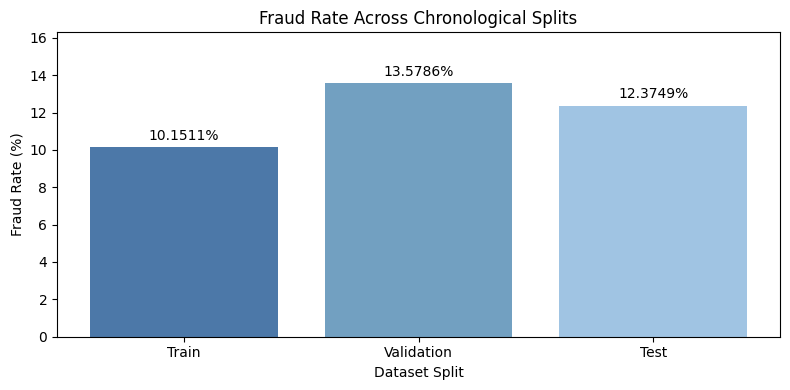

In [63]:
fig, ax = plt.subplots(figsize=(8, 4))

bars = ax.bar(
    split_summary["Split"],
    split_summary["Fraud Rate (%)"],
    color=["#4C78A8", "#72A0C1", "#A0C4E3"]
)

ax.bar_label(bars, fmt="%.4f%%", padding=3)

ax.set_title("Fraud Rate Across Chronological Splits")
ax.set_xlabel("Dataset Split")
ax.set_ylabel("Fraud Rate (%)")
ax.set_ylim(
    0,
    split_summary["Fraud Rate (%)"].max() * 1.2
)

plt.tight_layout()
plt.show()

### Observations

- Both datasets contain identical order records and fraud
  labels, ensuring a fair comparison.
- The training dataset is imbalanced, with only 10.15%
  of orders labelled as fraudulent.
- The fraud rate increases to 13.58% in the validation
  set and is 12.37% in the test set.
- This indicates a change in class distribution over time,
  which may affect model generalisation.
- Precision and recall are therefore more informative
  than accuracy alone for evaluating fraud detection.
- The chronological split provides a more realistic
  evaluation of performance on future orders.

## 7. Model-Specific Exploratory Data Analysis

### 7.1 Descriptive Statistics of Training Features

Examine the statistical properties of the training features,
including their mean, standard deviation, minimum,
maximum and quartiles.

This helps identify differences in feature scales,
potentially skewed distributions and constant features
before fitting Logistic Regression.

In [64]:
X_train_full = X_full.loc[train_mask]

unique_counts = X_train_full.nunique()

# Separate non-binary and binary features
non_binary_features = unique_counts[
    unique_counts > 2
].index

binary_features = unique_counts[
    unique_counts <= 2
].index

# Descriptive statistics for non-binary features
training_statistics = (
    X_train_full[non_binary_features]
    .describe()
    .T
    .drop(columns="count")
    .round(4)
)

training_statistics.insert(
    0,
    "Dataset",
    [
        "Safe & Full" if col in X_safe.columns
        else "Full only"
        for col in training_statistics.index
    ]
)

display(training_statistics)

,Dataset,mean,std,min,25%,50%,75%,max
value_per_item,Safe & Full,2.8401,2.6217,0.0000,1.3982,2.2288,3.3929,146.6983
cancel_rate,Full only,0.0225,0.0668,0.0000,0.0000,0.0000,0.0167,1.0000
refund_rate,Full only,0.0295,0.0729,0.0000,0.0000,0.0000,0.0303,1.0000
avg_payment_per_order,Full only,13.0117,7.9874,0.0000,7.9551,12.3887,16.7389,781.9039
account_age_days,Safe & Full,929.2989,607.2502,0.0000,491.0000,927.0000,1242.0000,3967.0000
log_order_value,Safe & Full,1.8643,0.6390,0.0000,1.4470,1.8817,2.2563,6.4981
log_num_items_ordered,Safe & Full,1.2895,0.5572,0.6931,0.6931,1.0986,1.6094,7.3784
log_num_orders_last_50days,Full only,2.8940,1.1642,0.0000,2.1972,3.0445,3.7377,7.6793
log_num_cancelled_orders_last_50days,Full only,0.2947,0.5404,0.0000,0.0000,0.0000,0.6931,5.5607
log_num_refund_orders_last_50days,Full only,0.3850,0.6327,0.0000,0.0000,0.0000,0.6931,4.6821


In [65]:
constant_features = unique_counts[
    unique_counts == 1
].index.tolist()

print("Total features:", X_train_full.shape[1])
print("Non-binary features:", len(non_binary_features))
print("Binary or constant features:", len(binary_features))
print("Constant features:", len(constant_features))

display(
    pd.DataFrame({
        "Feature": constant_features,
        "Constant Value": [
            X_train_full[col].iloc[0]
            for col in constant_features
        ]
    })
)

Total features: 41
Non-binary features: 12
Binary or constant features: 29
Constant features: 1


,Feature,Constant Value
0,payment_method_other,0


### Observations and Implications

- Feature scales vary considerably. For example,
  account_age_days has a standard deviation of 607.25,
  whereas log_order_value has a standard deviation
  of approximately 0.64.

- Some numerical features have relatively large maximum
  values compared with their median values, indicating
  potentially long-tailed distributions.

- Binary indicators and one-hot encoded features
  have values of either 0 or 1.

- payment_method_other is constant in the training set
  and therefore provides no discriminative information
  during model training.

- The constant feature is retained to maintain the
  team's fixed feature schema and compatibility
  with future data.

- StandardScaler will be included in the Logistic
  Regression pipeline to address differences in feature
  scales and support regularised model optimisation.

- The scaler will be fitted on the training set only
  to prevent data leakage.

- Although retaining this feature maintains schema
compatibility, the model cannot learn its relationship
with fraud until sufficient variation is observed in
future training data.

### 7.2 Class Imbalance

The training target distribution is examined to understand
the extent of class imbalance and its potential impact
on Logistic Regression.

Only training data is used for model-specific exploratory
analysis to avoid using future information for model
development.

,Count,Percentage (%)
Not Fraud,598282,89.8489
Fraud,67594,10.1511


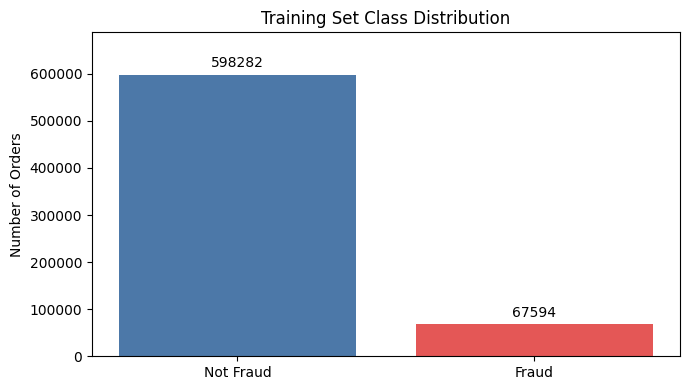

In [66]:
train_class_counts = (
    y[train_mask]
    .value_counts()
    .sort_index()
)

train_class_counts.index = [
    "Not Fraud", "Fraud"
]

class_distribution = pd.DataFrame({
    "Count": train_class_counts,
    "Percentage (%)": (
        train_class_counts /
        train_class_counts.sum() * 100
    ).round(4)
})

display(class_distribution)

fig, ax = plt.subplots(figsize=(7, 4))

bars = ax.bar(
    train_class_counts.index,
    train_class_counts.values,
    color=["#4C78A8", "#E45756"]
)

ax.bar_label(bars, fmt="%d", padding=3)

ax.set_title("Training Set Class Distribution")
ax.set_ylabel("Number of Orders")
ax.set_ylim(0, train_class_counts.max() * 1.15)

plt.tight_layout()
plt.show()

### Observations

Approximately 89.85% of the training orders are
non-fraudulent, while only 10.15% are fraudulent.

A model that predicts every order as non-fraudulent
could achieve approximately 89.85% training accuracy
without detecting any fraud.

Therefore, accuracy is insufficient for evaluating
the effectiveness of the fraud detection model.

Precision, recall, F1-score and Average Precision
provide more meaningful performance measures.

Class weighting and decision threshold adjustment
may be considered as potential improvement methods
if the model fails to achieve satisfactory performance.

### 7.3 Feature-Target Correlation

Pearson correlation is calculated between each prediction
feature and the binary fraud label using the training
set only.

For a binary target, this is equivalent to point-biserial
correlation.

The Safe and Full datasets are compared to identify
features that may contribute to fraud prediction.

Correlation indicates statistical association but does
not establish causation or guarantee predictive usefulness.

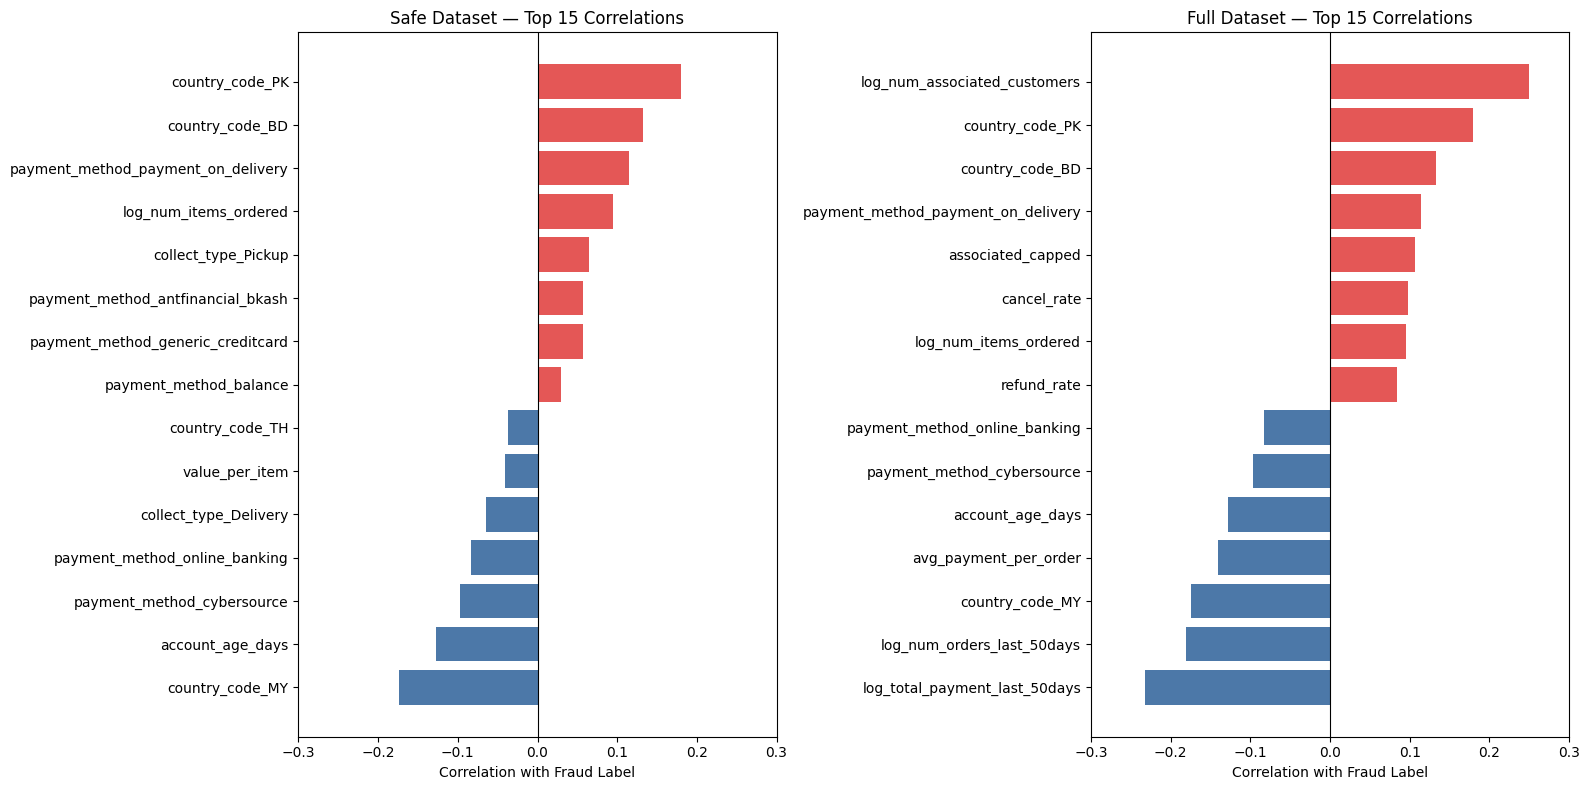

In [67]:
# Exclude constant features from correlation analysis only
non_constant_features = unique_counts[
    unique_counts > 1
].index

full_corr = X_train_full[
    non_constant_features
].corrwith(y.loc[train_mask])

safe_corr = full_corr.reindex(
    X_safe.columns
).dropna()

def get_top_correlations(corr, n=15):
    corr = corr.dropna()

    return corr.loc[
        corr.abs().nlargest(n).index
    ].sort_values()


fig, axes = plt.subplots(
    1, 2,
    figsize=(16, 8)
)

for ax, corr, name in [
    (axes[0], safe_corr, "Safe"),
    (axes[1], full_corr, "Full")
]:
    top_corr = get_top_correlations(corr)

    colors = [
        "#E45756" if value > 0 else "#4C78A8"
        for value in top_corr
    ]

    ax.barh(
        top_corr.index,
        top_corr.values,
        color=colors
    )

    ax.axvline(
        0,
        color="black",
        linewidth=0.8
    )

    ax.set_title(
        f"{name} Dataset — Top 15 Correlations"
    )

    ax.set_xlabel(
        "Correlation with Fraud Label"
    )

    ax.set_xlim(-0.30, 0.30)

plt.tight_layout()
plt.show()

### Observations

**Safe Dataset**

- Country indicators and payment methods show relatively
  stronger associations with the fraud label compared
  with other available features.
- Account age shows a negative correlation with fraud,
  suggesting that older accounts tend to have a lower
  observed fraud rate in the training data.
- Individual feature correlations are relatively weak,
  suggesting that fraud prediction may require combining
  information from multiple features.

**Full Dataset**

- Customer snapshot features introduce additional
  associations with the fraud label.
- The log-transformed number of associated customers
shows the strongest positive correlation with fraud
among the displayed features in the Full dataset.
- Historical payment amounts and order counts show
  notable negative correlations with fraud.
- These additional features may improve predictive
  performance, but their availability at prediction time
  must be confirmed to avoid temporal data leakage.

**Implications for Model Development**

- Logistic Regression provides an interpretable
  approach for assessing the combined contribution
  of these predictors.
- Correlation alone does not establish causation
  or determine model performance.
- Country-related features should be interpreted carefully,
  as observed associations may reflect differences in
  transaction patterns, sampling or market conditions.
- Both datasets will be evaluated using the same
  chronological splits and evaluation metrics.

### 7.4 Multicollinearity Analysis

Highly correlated predictors may affect the stability
and interpretability of Logistic Regression coefficients.

Pairwise Pearson correlations are examined using only
the training data. Feature pairs with an absolute
correlation of at least 0.8 are identified.

The original feature sets are retained to ensure
consistency with the team's shared feature definitions.

L2 regularisation will be used to mitigate the effects
of correlated predictors.

In [68]:
# Calculate correlations using non-constant training features
feature_corr = X_train_full[
    non_constant_features
].corr()

# Select the upper triangle to avoid duplicate pairs
upper_triangle = feature_corr.where(
    np.triu(
        np.ones(feature_corr.shape),
        k=1
    ).astype(bool)
)

# Identify highly correlated feature pairs
high_corr_pairs = (
    upper_triangle.stack()
    .reset_index()
)

high_corr_pairs.columns = [
    "Feature 1",
    "Feature 2",
    "Correlation"
]

high_corr_pairs["Absolute Correlation"] = (
    high_corr_pairs["Correlation"].abs()
)

high_corr_pairs = high_corr_pairs[
    high_corr_pairs["Absolute Correlation"] >= 0.8
].sort_values(
    "Absolute Correlation",
    ascending=False
)

high_corr_pairs["Dataset"] = [
    "Safe & Full"
    if f1 in X_safe.columns and f2 in X_safe.columns
    else "Full only"
    for f1, f2 in zip(
        high_corr_pairs["Feature 1"],
        high_corr_pairs["Feature 2"]
    )
]

print(
    "Highly correlated feature pairs:",
    len(high_corr_pairs)
)

display(high_corr_pairs.round(4))

Highly correlated feature pairs: 2


,Feature 1,Feature 2,Correlation,Absolute Correlation,Dataset
609,collect_type_Delivery,collect_type_Pickup,-1.000,1.000,Safe & Full
376,log_num_orders_last_50days,log_total_payment_last_50days,0.909,0.909,Full only


### Observations and Implications

- collect_type_Delivery and collect_type_Pickup have
  a perfect negative correlation of -1.000 because
  they represent mutually exclusive collection types.

- log_num_orders_last_50days and
  log_total_payment_last_50days have a strong positive
  correlation of 0.909, indicating that customers with
  more historical orders tend to have higher total
  payment amounts.

- Highly correlated predictors may affect the stability
  and interpretation of Logistic Regression coefficients.

- Both feature sets are retained to maintain consistency
  with the team's shared dataset definitions.

- L2 regularisation will be used to mitigate coefficient
  instability and reduce overfitting, while preserving
  the team's original feature sets.

- Regularisation does not eliminate multicollinearity,
  so the individual coefficients of highly correlated
  predictors should still be interpreted cautiously.

- Removing redundant predictors may be considered as
  a potential future improvement if coefficient
  interpretability becomes a concern.

## 8. Model Configuration

Based on the exploratory data analysis, Logistic Regression
is configured using the following design decisions:

- StandardScaler is used to standardise features with
  substantially different numerical scales.
- L2 regularisation is used to mitigate coefficient
  instability associated with correlated predictors
  and reduce overfitting.
- The original feature schemas are retained to ensure
  consistency with the team's shared datasets.
- No class weighting is applied in the initial experiments,
  allowing the model's natural precision-recall trade-off
  to be evaluated.
- A decision threshold of 0.5 is used consistently
  across both model versions.
- Identical hyperparameters are used for both versions
  to isolate the effect of different feature sets.

The scaler and classifier are combined into a single
scikit-learn Pipeline to prevent preprocessing leakage
and support reproducible training and inference.

In [70]:
MODEL_PARAMS = {
    "penalty": "l2",
    "C": 1.0,
    "solver": "lbfgs",
    "max_iter": 1000,
    "class_weight": None,
    "random_state": RANDOM_STATE
}

THRESHOLD = 0.5


def build_logistic_regression():
    """Create a fresh Logistic Regression pipeline."""

    return Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", LogisticRegression(
            **MODEL_PARAMS
        ))
    ])


display(pd.DataFrame(
    MODEL_PARAMS.items(),
    columns=["Parameter", "Value"]
))

,Parameter,Value
0,penalty,l2
1,C,1.0
2,solver,lbfgs
3,max_iter,1000
4,class_weight,None
5,random_state,42


### 8.1 MLflow Experiment Configuration

The shared MLflow utilities are used to record model
parameters, evaluation metrics, trained models and
evaluation artifacts.

During model development, experiments are recorded in
a persistent local MLflow tracking server.

The tracking server can subsequently be changed through
environment configuration without modifying the model
training logic.

In [71]:
import mlflow

# Local development configuration
os.environ.setdefault(
    "MLFLOW_TRACKING_URI",
    "http://127.0.0.1:5004"
)

EXPERIMENT_NAME = "SP-buy-Fraud-Detection"

connect_mlflow(
    experiment_name=EXPERIMENT_NAME
)

2026/11/25 17:09:40 INFO mlflow.tracking.fluent: Experiment with name 'SP-buy-Fraud-Detection' does not exist. Creating a new experiment.


MLflow Tracking URI: http://127.0.0.1:5004
Experiment: SP-buy-Fraud-Detection


## 9. Version 1 — Logistic Regression (Safe Dataset)

### 9.1 Training Data Preparation

Version 1 uses the Safe dataset containing 31 prediction
features.

The restricted feature set excludes customer snapshot
features whose availability at prediction time has not
been confirmed.

The shared chronological split is retained to ensure
consistent evaluation across all team models.

In [72]:
X_train_safe = X_safe.loc[train_mask]
X_val_safe = X_safe.loc[val_mask]
X_test_safe = X_safe.loc[test_mask]

y_train = y.loc[train_mask]
y_val = y.loc[val_mask]
y_test = y.loc[test_mask]

safe_split_summary = pd.DataFrame({
    "Split": ["Train", "Validation", "Test"],
    "Records": [
        len(X_train_safe),
        len(X_val_safe),
        len(X_test_safe)
    ],
    "Features": [
        X_train_safe.shape[1],
        X_val_safe.shape[1],
        X_test_safe.shape[1]
    ],
    "Fraud Cases": [
        y_train.sum(),
        y_val.sum(),
        y_test.sum()
    ]
})

display(safe_split_summary)

,Split,Records,Features,Fraud Cases
0,Train,665876,31,67594
1,Validation,139874,31,18993
2,Test,144122,31,17835


### 9.2 Model Training

A Logistic Regression pipeline is fitted using the Safe
training dataset.

The StandardScaler is fitted exclusively on the training
features before the classifier is trained.

Training duration and convergence are recorded to assess
computational efficiency and suitability for the automated
retraining pipeline.

In [73]:
# Create the Safe model pipeline
model_safe = build_logistic_regression()

# Record training time
start_time = time.perf_counter()

model_safe.fit(
    X_train_safe,
    y_train
)

training_time_safe = (
    time.perf_counter() - start_time
)

# Retrieve classifier information
classifier_safe = model_safe.named_steps["classifier"]

iterations_safe = int(
    classifier_safe.n_iter_.max()
)

print("Model: Logistic Regression")
print("Version: V1 - Safe Dataset")
print("Training records:", len(X_train_safe))
print("Number of features:", X_train_safe.shape[1])
print(f"Training time: {training_time_safe:.4f} seconds")
print("Iterations used:", iterations_safe)
print("Maximum iterations:", MODEL_PARAMS["max_iter"])

if iterations_safe < MODEL_PARAMS["max_iter"]:
    print("Convergence check: Passed")
else:
    print("Convergence check: Review required")

Model: Logistic Regression
Version: V1 - Safe Dataset
Training records: 665876
Number of features: 31
Training time: 1.9473 seconds
Iterations used: 13
Maximum iterations: 1000
Convergence check: Passed


### Training Observations

- The Logistic Regression pipeline was successfully
  trained on 665,876 orders using 31 prediction features.
- Model training took approximately 1.95 seconds,
  demonstrating good computational efficiency.
- The optimiser completed training in 13 iterations,
  well below the maximum limit of 1,000 iterations.
- No convergence warning was observed, suggesting that
  the current scaling and solver configuration is suitable.
- The short training duration makes Logistic Regression
  a promising candidate for automated retraining.

Predictive performance must still be evaluated before
determining whether the model satisfies the stakeholder's
fraud detection requirements.

### 9.3 Validation Predictions

The trained model generates fraud probabilities for
the validation dataset.

A fixed decision threshold of 0.5 is used to convert
the predicted probabilities into binary classifications.

The validation results are used to assess model
performance and identify potential limitations.

In [75]:
# Generate fraud probabilities
y_train_prob_safe = model_safe.predict_proba(
    X_train_safe
)[:, 1]

y_val_prob_safe = model_safe.predict_proba(
    X_val_safe
)[:, 1]

# Convert probabilities into class predictions
y_val_pred_safe = (
    y_val_prob_safe >= THRESHOLD
).astype(int)

prediction_summary_safe = pd.DataFrame({
    "Actual": y_val.to_numpy(),
    "Fraud Probability": y_val_prob_safe,
    "Predicted": y_val_pred_safe
})

display(prediction_summary_safe.head(10))

print("Validation records:", len(y_val))
print("Actual fraud cases:", y_val.sum())
print("Predicted fraud cases:", y_val_pred_safe.sum())
print("Decision threshold:", THRESHOLD)

,Actual,Fraud Probability,Predicted
0,0,0.066812,0
1,0,0.067537,0
2,0,0.054235,0
3,0,0.107510,0
4,1,0.208076,0
5,0,0.037668,0
6,1,0.157350,0
7,0,0.017146,0
8,0,0.139818,0
9,1,0.080340,0


Validation records: 139874
Actual fraud cases: 18993
Predicted fraud cases: 1316
Decision threshold: 0.5


### 9.4 Evaluation and MLflow Experiment Logging

The shared MLflow logging utilities are used to record:

- Model hyperparameters and training configuration.
- Training duration and convergence information.
- Training and validation evaluation metrics.
- The trained preprocessing and classification pipeline.
- Confusion matrix and precision-recall curve.
- Prediction feature metadata.

Training and validation metrics are recorded to
identify potential overfitting or underfitting.

The test dataset is reserved for final evaluation
after both model versions have been configured.

In [76]:
with start_model_run(
    member="abby",
    algorithm="logistic_regression",
    dataset_version="safe",
    model_version="v1"
) as run:

    run_id_safe = run.info.run_id

    # 1. Record model configuration
    log_model_parameters(
        model_params=MODEL_PARAMS,
        threshold=THRESHOLD,
        feature_count=X_train_safe.shape[1]
    )

    mlflow.log_params({
        "scaler": "StandardScaler",
        "training_records": len(X_train_safe),
        "validation_records": len(X_val_safe)
    })

    # 2. Record computational performance
    mlflow.log_metrics({
        "training_time_seconds": training_time_safe,
        "iterations_used": iterations_safe
    })

    # 3. Record training metrics
    train_metrics_safe = log_classification_metrics(
        y_true=y_train,
        y_prob=y_train_prob_safe,
        threshold=THRESHOLD,
        split="train"
    )

    # 4. Record validation metrics
    val_metrics_safe = log_classification_metrics(
        y_true=y_val,
        y_prob=y_val_prob_safe,
        threshold=THRESHOLD,
        split="val"
    )

    # 5. Save trained model pipeline
    model_info_safe = log_trained_model(
        model=model_safe,
        X_sample=X_train_safe.head(5),
        model_name="logistic_regression_safe"
    )

    # 6. Save evaluation artifacts
    log_evaluation_artifacts(
        y_true=y_val,
        y_prob=y_val_prob_safe,
        feature_names=X_train_safe.columns,
        threshold=THRESHOLD,
        split="val"
    )

print("MLflow logging completed.")
print("Run ID:", run_id_safe)
print("Model URI:", model_info_safe.model_uri)

c:\Users\User\OneDrive - Singapore Polytechnic\Desktop\MLOps_CA1_group5\.venv\Lib\site-packages\mlflow\types\utils.py:440: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details.
  warnings.warn(


🏃 View run abby_logistic_regression_safe_v1 at: http://127.0.0.1:5004/#/experiments/1/runs/53cba4b45adf40549f43e9d523ffc17e
🧪 View experiment at: http://127.0.0.1:5004/#/experiments/1
MLflow logging completed.
Run ID: 53cba4b45adf40549f43e9d523ffc17e
Model URI: models:/m-4b2ddf96b3434c03a351061563d86204


### 9.5 Training and Validation Performance

The training and validation metrics are compared to
assess predictive performance and generalisation.

Precision is prioritised in accordance with the
stakeholder's requirements, while recall, F1-score,
Average Precision and ROC-AUC provide complementary
measures of model effectiveness.

In [77]:
metric_names = [
    "accuracy",
    "precision",
    "recall",
    "f1",
    "pr_auc",
    "roc_auc"
]

metric_labels = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1-score",
    "PR-AUC (Average Precision)",
    "ROC-AUC"
]

performance_safe = pd.DataFrame({
    "Metric": metric_labels,
    "Training": [
        train_metrics_safe[f"train_{m}"]
        for m in metric_names
    ],
    "Validation": [
        val_metrics_safe[f"val_{m}"]
        for m in metric_names
    ]
})

performance_safe["Gap (Train - Val)"] = (
    performance_safe["Training"] -
    performance_safe["Validation"]
)

display(performance_safe.round(4))

,Metric,Training,Validation,Gap (Train - Val)
0,Accuracy,0.9005,0.8692,0.0313
1,Precision,0.6018,0.7667,-0.1649
2,Recall,0.0589,0.0531,0.0058
3,F1-score,0.1073,0.0994,0.0079
4,PR-AUC (Average Precision),0.3165,0.4586,-0.1421
5,ROC-AUC,0.7741,0.7924,-0.0183


### 9.6 Performance Comparison Chart

The training and validation metrics are visualised
to identify performance differences and potential
generalisation issues.

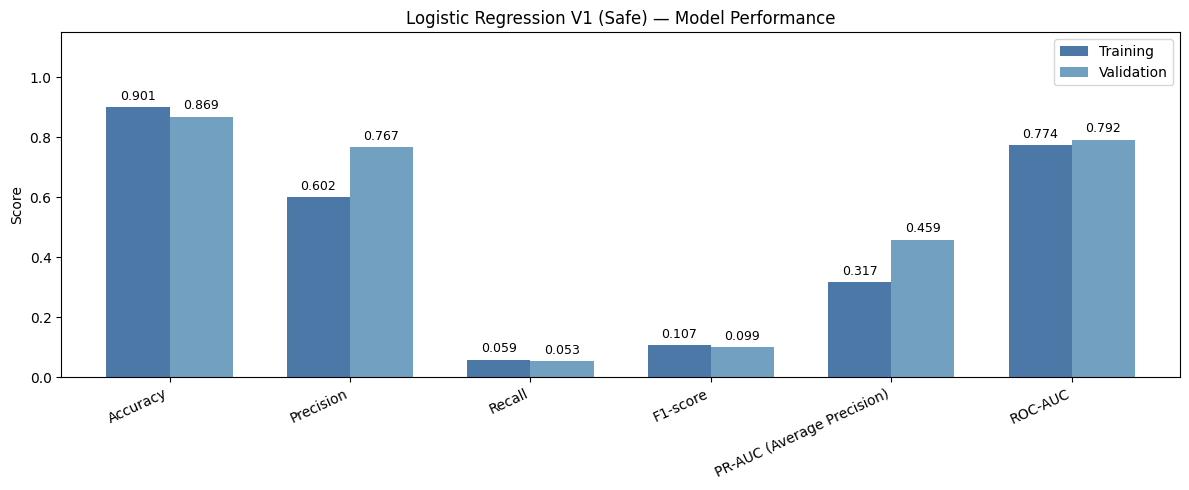

In [78]:
ax = performance_safe.plot(
    x="Metric",
    y=["Training", "Validation"],
    kind="bar",
    figsize=(12, 5),
    color=["#4C78A8", "#72A0C1"],
    width=0.7
)

for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.3f",
        padding=3,
        fontsize=9
    )

ax.set_title(
    "Logistic Regression V1 (Safe) — Model Performance"
)

ax.set_ylabel("Score")
ax.set_xlabel("")
ax.set_ylim(0, 1.15)

plt.xticks(rotation=25, ha="right")
plt.legend(loc="upper right")
plt.tight_layout()
plt.show()

#### Observations

- Validation precision increased from 60.18% to 76.67%.
- Average Precision improved from 0.3165 to 0.4586,
  while ROC-AUC increased from 0.7741 to 0.7924.
- Recall remained extremely low across both datasets,
  indicating that the model detects only a small
  proportion of fraudulent orders.
- There is no clear evidence of severe overfitting.
  However, differences in fraud prevalence across
  chronological splits may influence the results.

### 9.7 Confusion Matrix and Error Analysis

The validation confusion matrix is examined to identify
the types of classification errors made by the model.

False positives represent legitimate orders incorrectly
flagged for investigation, while false negatives represent
fraudulent orders that remain undetected.

Both error types are important because the stakeholder
prioritises high precision while maintaining reasonable
recall.

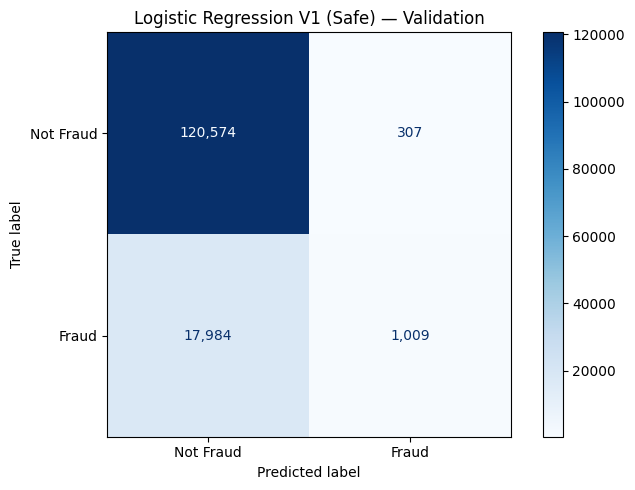

,Classification,Count
0,True Negative,120574
1,False Positive,307
2,False Negative,17984
3,True Positive,1009


Fraud detection rate: 5.31%
Fraud missed rate: 94.69%
False positive rate: 0.25%


In [79]:
from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay
)

cm_safe = confusion_matrix(
    y_val,
    y_val_pred_safe,
    labels=[0, 1]
)

tn, fp, fn, tp = cm_safe.ravel()

fig, ax = plt.subplots(figsize=(7, 5))

ConfusionMatrixDisplay(
    confusion_matrix=cm_safe,
    display_labels=["Not Fraud", "Fraud"]
).plot(
    cmap="Blues",
    values_format=",d",
    ax=ax
)

ax.set_title(
    "Logistic Regression V1 (Safe) — Validation"
)

plt.tight_layout()
plt.show()

error_summary_safe = pd.DataFrame({
    "Classification": [
        "True Negative",
        "False Positive",
        "False Negative",
        "True Positive"
    ],
    "Count": [tn, fp, fn, tp]
})

display(error_summary_safe)

print(f"Fraud detection rate: {tp / (tp + fn):.2%}")
print(f"Fraud missed rate: {fn / (tp + fn):.2%}")
print(f"False positive rate: {fp / (fp + tn):.2%}")

### Confusion Matrix Observations

- The model correctly identified 120,574 legitimate
  orders and 1,009 fraudulent orders.
- Only 307 legitimate orders were incorrectly flagged,
  resulting in a low false positive rate of 0.25%.
- However, 17,984 fraudulent orders remained undetected,
  resulting in a fraud missed rate of 94.69%.
- The model demonstrates conservative fraud detection
  behaviour at the default decision threshold of 0.5.
- Although this supports the stakeholder's objective of
  minimising unnecessary investigations, the low recall
  does not adequately satisfy the requirement to maintain
  reasonable fraud detection coverage.

### 9.8 ROC and Precision-Recall Curves

ROC-AUC and Average Precision assess the model's
ability to rank fraudulent orders across different
classification thresholds.

The precision-recall curve is particularly relevant
because the dataset is imbalanced and the stakeholder
prioritises precision while requiring reasonable recall.

These curves help determine whether threshold adjustment
could improve the model's operational performance.

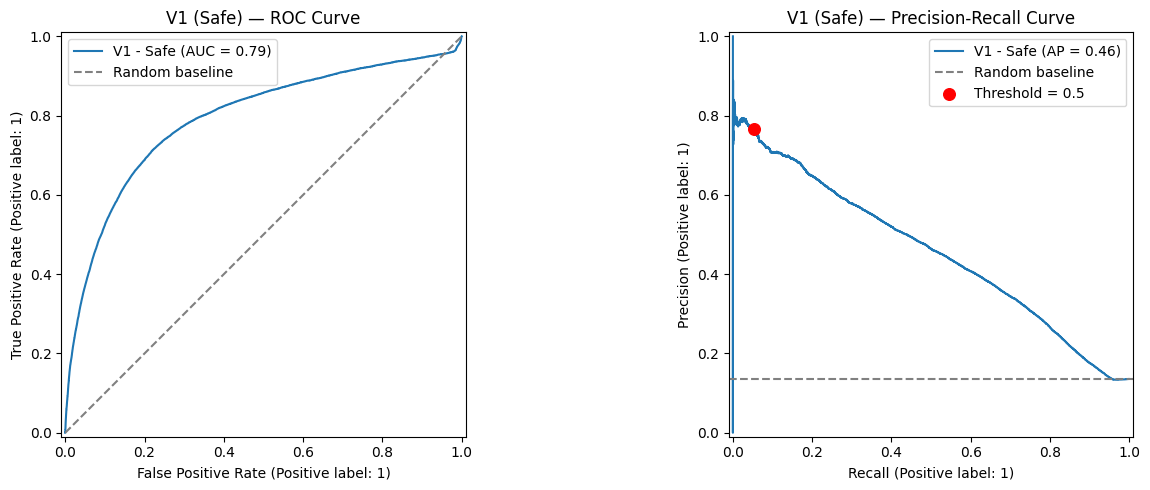

In [94]:
from sklearn.metrics import RocCurveDisplay, PrecisionRecallDisplay

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
RocCurveDisplay.from_predictions(y_val, y_val_prob_safe, name="V1 - Safe", ax=axes[0])
axes[0].plot([0, 1], [0, 1], "--", color="grey", label="Random baseline")
axes[0].set_title("V1 (Safe) — ROC Curve")
axes[0].legend()

PrecisionRecallDisplay.from_predictions(y_val, y_val_prob_safe, name="V1 - Safe", ax=axes[1])
axes[1].axhline(y_val.mean(), linestyle="--", color="grey", label="Random baseline")
axes[1].scatter(val_metrics_safe["val_recall"], val_metrics_safe["val_precision"], color="red", s=70, zorder=5, label="Threshold = 0.5")
axes[1].set_title("V1 (Safe) — Precision-Recall Curve")
axes[1].legend()
plt.tight_layout()
plt.show()

#### Observations

- Validation ROC-AUC is 0.7924 and AP is 0.4586, exceeding the random ranking baselines of 0.5 and approximately 0.1358, respectively.
- The default operating point achieves 76.67% precision but only 5.31% recall. This motivates a validation-only investigation of alternative thresholds.

### 9.9 Performance Diagnosis

**Predictive performance**

The Safe Logistic Regression model achieved a validation
precision of 76.67%, indicating that most flagged orders
were genuinely fraudulent. However, its recall was only
5.31%, meaning that approximately 94.69% of fraudulent
orders remained undetected.

Although this model demonstrates promising precision,
its extremely low recall prevents it from fully satisfying
the stakeholder's requirement of high precision with
reasonable recall.

**Generalisation**

Validation precision, Average Precision and ROC-AUC
were higher than their corresponding training values.
There is therefore no clear evidence of severe overfitting.

However, differences in fraud prevalence across the
chronological splits should be considered when interpreting
these performance differences.

**Classification limitations**

The model achieved a validation ROC-AUC of 0.7924 and
Average Precision of 0.4586, suggesting that it possesses
some ability to distinguish fraudulent from legitimate
orders.

Its poor recall at the default threshold of 0.5 suggests
that the current classification threshold may be too
conservative.

Class imbalance and the linear decision boundary may also
limit its ability to identify complex fraud patterns.

**Computational efficiency**

The model completed training in approximately 1.95 seconds
and converged within 13 iterations. This demonstrates good
training efficiency and makes it a promising candidate
for automated retraining.

**Business assessment**

The model is computationally efficient and provides
relatively high precision, but further investigation
is required to achieve a more suitable precision-recall
trade-off before it can be considered for deployment.

## 10. Version 2 — Logistic Regression (Full Dataset)

### 10.1 Training Data Preparation

Version 2 uses the Full dataset containing 41 prediction
features, including 10 additional customer snapshot
features.

The same chronological split, preprocessing pipeline,
hyperparameters and decision threshold are retained
to isolate the effect of the additional features.

This version is intended for exploratory comparison,
as the availability of customer snapshot features at
the actual time of fraud assessment remains uncertain.

In [81]:
X_train_full = X_full.loc[train_mask]
X_val_full = X_full.loc[val_mask]
X_test_full = X_full.loc[test_mask]

full_split_summary = pd.DataFrame({
    "Split": ["Train", "Validation", "Test"],
    "Records": [
        len(X_train_full),
        len(X_val_full),
        len(X_test_full)
    ],
    "Features": [
        X_train_full.shape[1],
        X_val_full.shape[1],
        X_test_full.shape[1]
    ],
    "Fraud Cases": [
        y_train.sum(),
        y_val.sum(),
        y_test.sum()
    ]
})

display(full_split_summary)

,Split,Records,Features,Fraud Cases
0,Train,665876,41,67594
1,Validation,139874,41,18993
2,Test,144122,41,17835


#### Observations

- The Full dataset contains 41 prediction features,
  compared with 31 features in the Safe dataset.
- Training, validation and testing record counts
  are identical across both versions.
- The number of fraudulent orders is also identical
  within each chronological split.
- This ensures that performance differences can be
  evaluated under consistent data conditions.
- The additional customer snapshot features are
  retained for exploratory comparison, as their
  point-in-time availability remains uncertain.

### 10.2 Model Training

A new Logistic Regression pipeline is trained using
the Full training dataset.

The same model configuration as Version 1 is reused
to ensure a controlled comparison between the two
feature sets.

Training duration and convergence are recorded to
evaluate the computational impact of the additional
customer snapshot features.

In [82]:
model_full = build_logistic_regression()

start_time = time.perf_counter()

model_full.fit(
    X_train_full,
    y_train
)

training_time_full = (
    time.perf_counter() - start_time
)

classifier_full = model_full.named_steps["classifier"]

iterations_full = int(
    classifier_full.n_iter_.max()
)

print("Model: Logistic Regression")
print("Version: V2 - Full Dataset")
print("Training records:", len(X_train_full))
print("Number of features:", X_train_full.shape[1])
print(f"Training time: {training_time_full:.4f} seconds")
print("Iterations used:", iterations_full)
print("Maximum iterations:", MODEL_PARAMS["max_iter"])

if iterations_full < MODEL_PARAMS["max_iter"]:
    print("Convergence check: Passed")
else:
    print("Convergence check: Review required")


Model: Logistic Regression
Version: V2 - Full Dataset
Training records: 665876
Number of features: 41
Training time: 3.5282 seconds
Iterations used: 22
Maximum iterations: 1000
Convergence check: Passed


#### Training Observations

- The Full pipeline trained on 665,876 orders and 41 features in approximately 3.53 seconds.
- The optimiser completed 22 iterations, below the limit of 1,000, and the convergence check passed.
- The observed fitting time is longer than V1 (1.95 seconds), but both versions train quickly. This does not establish the runtime of the complete automated retraining pipeline.

### 10.3 Validation Predictions

Fraud probabilities are generated using the trained
Full Logistic Regression model.

The same decision threshold of 0.5 is applied to
ensure a fair comparison with Version 1.

In [83]:
y_train_prob_full = model_full.predict_proba(
    X_train_full
)[:, 1]

y_val_prob_full = model_full.predict_proba(
    X_val_full
)[:, 1]

y_val_pred_full = (
    y_val_prob_full >= THRESHOLD
).astype(int)

prediction_summary_full = pd.DataFrame({
    "Actual": y_val.to_numpy(),
    "Fraud Probability": y_val_prob_full,
    "Predicted": y_val_pred_full
})

display(prediction_summary_full.head(10))

print("Validation records:", len(y_val))
print("Actual fraud cases:", y_val.sum())
print("Predicted fraud cases:", y_val_pred_full.sum())
print("Decision threshold:", THRESHOLD)

,Actual,Fraud Probability,Predicted
0,0,0.041867,0
1,0,0.023009,0
2,0,0.116129,0
3,0,0.021108,0
4,1,0.094832,0
5,0,0.033642,0
6,1,0.193773,0
7,0,0.008029,0
8,0,0.097925,0
9,1,0.443141,0


Validation records: 139874
Actual fraud cases: 18993
Predicted fraud cases: 4866
Decision threshold: 0.5


#### Prediction Observations

At the fixed threshold of 0.5, V2 flags 4,866 validation orders, compared with 1,316 for V1. The larger number of alerts does not necessarily mean better fraud detection; the confusion matrix and precision-recall metrics are needed to assess alert quality and coverage.

### 10.4 Evaluation and MLflow Experiment Logging

The same shared MLflow utilities are used to record
the Full model's configuration, computational performance,
evaluation metrics, trained pipeline and evaluation artifacts.

Consistent logging enables direct comparison between
Version 1 and Version 2 in MLflow.

In [84]:
with start_model_run(
    member="abby",
    algorithm="logistic_regression",
    dataset_version="full",
    model_version="v2"
) as run:

    run_id_full = run.info.run_id

    # Record model configuration
    log_model_parameters(
        model_params=MODEL_PARAMS,
        threshold=THRESHOLD,
        feature_count=X_train_full.shape[1]
    )

    mlflow.log_params({
        "scaler": "StandardScaler",
        "training_records": len(X_train_full),
        "validation_records": len(X_val_full)
    })

    # Record potential temporal leakage risk
    mlflow.set_tags({
        "deployment_eligibility": "exploratory_only",
        "snapshot_availability": "unconfirmed"
    })

    # Record computational performance
    mlflow.log_metrics({
        "training_time_seconds": training_time_full,
        "iterations_used": iterations_full
    })

    # Training evaluation
    train_metrics_full = log_classification_metrics(
        y_true=y_train,
        y_prob=y_train_prob_full,
        threshold=THRESHOLD,
        split="train"
    )

    # Validation evaluation
    val_metrics_full = log_classification_metrics(
        y_true=y_val,
        y_prob=y_val_prob_full,
        threshold=THRESHOLD,
        split="val"
    )

    # Save trained pipeline
    model_info_full = log_trained_model(
        model=model_full,
        X_sample=X_train_full.head(5),
        model_name="logistic_regression_full"
    )

    # Save evaluation artifacts
    log_evaluation_artifacts(
        y_true=y_val,
        y_prob=y_val_prob_full,
        feature_names=X_train_full.columns,
        threshold=THRESHOLD,
        split="val"
    )

print("MLflow logging completed.")
print("Run ID:", run_id_full)
print("Model URI:", model_info_full.model_uri)

c:\Users\User\OneDrive - Singapore Polytechnic\Desktop\MLOps_CA1_group5\.venv\Lib\site-packages\mlflow\types\utils.py:440: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details.
  warnings.warn(


🏃 View run abby_logistic_regression_full_v2 at: http://127.0.0.1:5004/#/experiments/1/runs/86b4be614e394fa2ac73d90c6508dcb3
🧪 View experiment at: http://127.0.0.1:5004/#/experiments/1
MLflow logging completed.
Run ID: 86b4be614e394fa2ac73d90c6508dcb3
Model URI: models:/m-180bf5ed2c4c4996a2d36e793fdb34c7


### 10.5 Training and Validation Performance

Compare training and validation accuracy, precision, recall, F1-score, Average Precision (AP) and ROC-AUC. The train–validation gaps help assess generalisation, while precision and recall are interpreted in relation to the stakeholder's fraud detection priorities.

In [85]:
performance_full = pd.DataFrame({
    "Metric": metric_labels,
    "Training": [
        train_metrics_full[f"train_{m}"]
        for m in metric_names
    ],
    "Validation": [
        val_metrics_full[f"val_{m}"]
        for m in metric_names
    ]
})

performance_full["Gap (Train - Val)"] = (
    performance_full["Training"] -
    performance_full["Validation"]
)

display(performance_full.round(4))

,Metric,Training,Validation,Gap (Train - Val)
0,Accuracy,0.9039,0.8743,0.0296
1,Precision,0.5806,0.6453,-0.0647
2,Recall,0.1925,0.1653,0.0271
3,F1-score,0.2891,0.2632,0.0259
4,PR-AUC (Average Precision),0.4309,0.4691,-0.0382
5,ROC-AUC,0.8600,0.8238,0.0362


#### Performance Visualisation

Display the training and validation scores side by side to make the metric gaps easier to interpret.

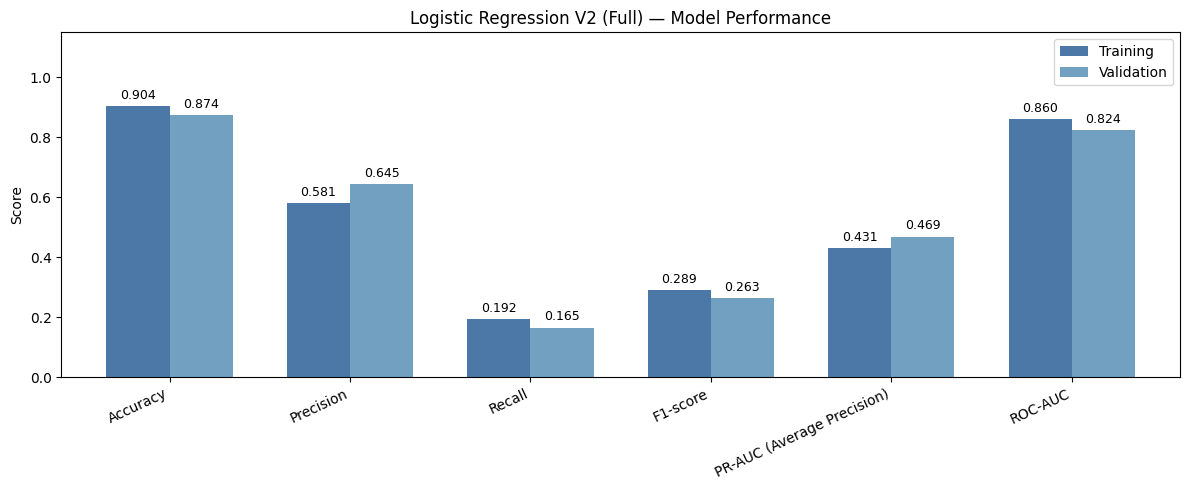

In [86]:
ax = performance_full.plot(
    x="Metric",
    y=["Training", "Validation"],
    kind="bar",
    figsize=(12, 5),
    color=["#4C78A8", "#72A0C1"],
    width=0.7
)

for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.3f",
        padding=3,
        fontsize=9
    )

ax.set_title(
    "Logistic Regression V2 (Full) — Model Performance"
)

ax.set_ylabel("Score")
ax.set_xlabel("")
ax.set_ylim(0, 1.15)

plt.xticks(rotation=25, ha="right")
plt.legend(loc="upper right")
plt.tight_layout()
plt.show()

#### Performance Observations

- Validation precision is 64.53% and recall is 16.53%, compared with training precision of 58.06% and recall of 19.25%.
- Validation AP increases from 0.4309 to 0.4691, while ROC-AUC decreases from 0.8600 to 0.8238.
- Recall remains limited and F1-score decreases from 0.2891 to 0.2632. Accuracy alone is not sufficient to establish suitability for fraud detection.

### 10.6 Confusion Matrix and Error Analysis

Examine the validation confusion matrix at the fixed threshold of 0.5. False positives represent unnecessary investigations of legitimate orders, while false negatives represent fraud cases that remain undetected.

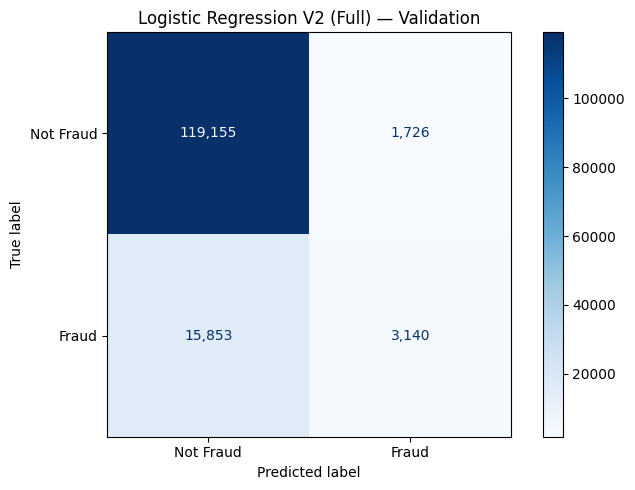

,Classification,Count
0,True Negative,119155
1,False Positive,1726
2,False Negative,15853
3,True Positive,3140


Fraud detection rate: 16.53%
Fraud missed rate: 83.47%
False positive rate: 1.43%


In [87]:
cm_full = confusion_matrix(
    y_val,
    y_val_pred_full,
    labels=[0, 1]
)

tn_full, fp_full, fn_full, tp_full = cm_full.ravel()

fig, ax = plt.subplots(figsize=(7, 5))

ConfusionMatrixDisplay(
    confusion_matrix=cm_full,
    display_labels=["Not Fraud", "Fraud"]
).plot(
    cmap="Blues",
    values_format=",d",
    ax=ax
)

ax.set_title(
    "Logistic Regression V2 (Full) — Validation"
)

plt.tight_layout()
plt.show()

error_summary_full = pd.DataFrame({
    "Classification": [
        "True Negative",
        "False Positive",
        "False Negative",
        "True Positive"
    ],
    "Count": [
        tn_full, fp_full, fn_full, tp_full
    ]
})

display(error_summary_full)

print(f"Fraud detection rate: {tp_full / (tp_full + fn_full):.2%}")
print(f"Fraud missed rate: {fn_full / (tp_full + fn_full):.2%}")
print(f"False positive rate: {fp_full / (fp_full + tn_full):.2%}")

#### Confusion Matrix Observations

- V2 correctly detects 3,140 fraudulent orders and 119,155 legitimate orders.
- It incorrectly flags 1,726 legitimate orders (false positive rate: 1.43%) and misses 15,853 fraud cases (83.47% of actual fraud).
- Compared with V1, V2 detects 2,131 more fraud cases in total but also generates 1,419 more false positives. This represents a trade-off between fraud detection coverage and unnecessary investigations.
- Despite improved recall, the default operating point still leaves substantial fraud undetected.

### 10.7 Performance Diagnosis

**Predictive performance**

The Full Logistic Regression model achieved a validation
precision of 64.53% and recall of 16.53%.

Compared with Version 1, the additional customer snapshot
features improved fraud detection coverage but reduced
precision.

The model correctly detected 3,140 fraudulent orders,
while incorrectly flagging 1,726 legitimate orders.

Despite the improvement in recall, 83.47% of fraudulent
orders remained undetected.

**Generalisation**

Training and validation ROC-AUC values were 0.8600
and 0.8238, respectively.

The moderate performance gap suggests that further
investigation of generalisation is worthwhile. However,
there is insufficient evidence to conclude that the model
suffers from severe overfitting.

**Computational efficiency**

The model completed training in approximately 3.53 seconds
and converged within 22 iterations.

Although training took longer than Version 1, both
models demonstrate good fitting efficiency.

**Deployment limitations**

The Full dataset includes customer snapshot features whose
availability at the time of fraud assessment is uncertain.

Therefore, the model is retained for exploratory comparison
and should not be selected for deployment unless the
point-in-time availability of these features is verified.

## 11. Safe vs Full Model Comparison

Both Logistic Regression versions are compared using
the same validation records, model hyperparameters
and decision threshold.

The comparison evaluates predictive performance,
business impact, computational efficiency and potential
temporal data leakage.

Model selection is guided by the stakeholder's requirement
to prioritise high precision while maintaining reasonable
recall.

### 11.1 Overall Performance Comparison

Compare the two versions on the same validation orders at a threshold of 0.5. The difference column reports Full minus Safe, isolating the observed effect of the additional customer snapshot features under the same training configuration.

In [88]:
comparison_lr = pd.DataFrame({
    "Metric": metric_labels,
    "V1 - Safe": [
        val_metrics_safe[f"val_{m}"]
        for m in metric_names
    ],
    "V2 - Full": [
        val_metrics_full[f"val_{m}"]
        for m in metric_names
    ]
})

comparison_lr["Difference (Full - Safe)"] = (
    comparison_lr["V2 - Full"] -
    comparison_lr["V1 - Safe"]
)

display(comparison_lr.round(4))

,Metric,V1 - Safe,V2 - Full,Difference (Full - Safe)
0,Accuracy,0.8692,0.8743,0.0051
1,Precision,0.7667,0.6453,-0.1214
2,Recall,0.0531,0.1653,0.1122
3,F1-score,0.0994,0.2632,0.1638
4,PR-AUC (Average Precision),0.4586,0.4691,0.0105
5,ROC-AUC,0.7924,0.8238,0.0314


#### Validation Performance Visualisation

Visualise both versions using the same metric scale. Pay particular attention to precision and recall rather than ranking models by accuracy alone.

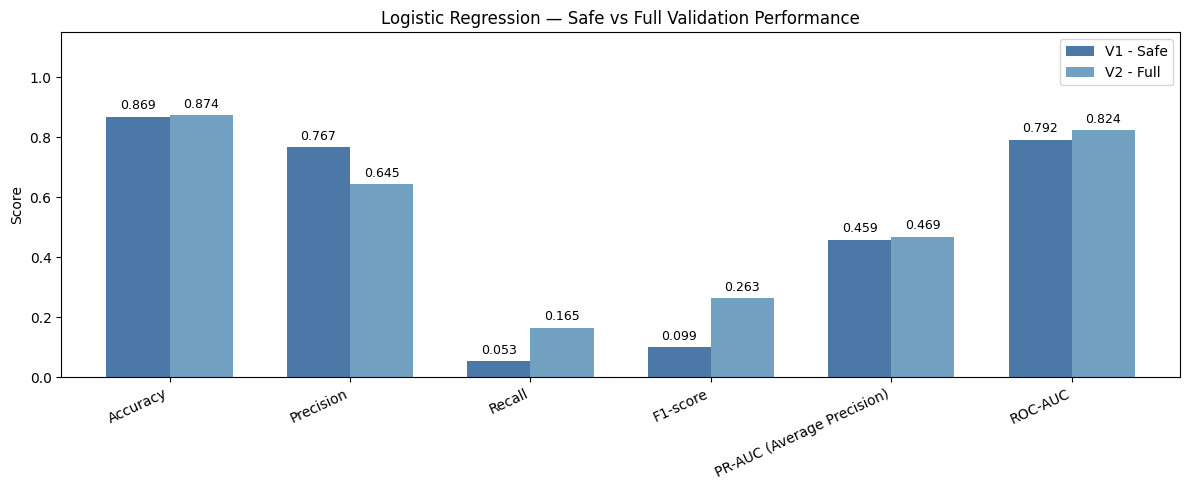

In [89]:
ax = comparison_lr.plot(
    x="Metric",
    y=["V1 - Safe", "V2 - Full"],
    kind="bar",
    figsize=(12, 5),
    color=["#4C78A8", "#72A0C1"],
    width=0.7
)

for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.3f",
        padding=3,
        fontsize=9
    )

ax.set_title(
    "Logistic Regression — Safe vs Full Validation Performance"
)

ax.set_ylabel("Score")
ax.set_xlabel("")
ax.set_ylim(0, 1.15)

plt.xticks(rotation=25, ha="right")
plt.legend()
plt.tight_layout()
plt.show()

#### Comparison Observations

- V1 achieves higher precision (76.67% versus 64.53%), a difference of 12.14 percentage points in favour of Safe.
- V2 achieves higher recall (16.53% versus 5.31%) and F1-score (0.2632 versus 0.0994), but generates more false positives.
- V2 improves ROC-AUC by 0.0314 and AP by only 0.0105. Its overall ranking improvement is modest in AP terms compared with its recall gain at the fixed threshold.
- Neither baseline achieves a satisfactory fraud coverage for the stated business objective. V1 is the more defensible candidate for further investigation because of lower temporal leakage risk, not because it is already deployment-ready. V2 remains exploratory until the extra features are verified.

### 11.2 Computational Efficiency Comparison

Compare feature counts, fitting times and optimiser iterations to assess the computational cost of including additional features. The recorded duration measures model fitting only, not the complete ETL or retraining pipeline.

In [90]:
efficiency_comparison = pd.DataFrame({
    "Metric": [
        "Number of features",
        "Training records",
        "Training time (seconds)",
        "Iterations used",
        "Maximum iterations",
        "Converged"
    ],
    "V1 - Safe": [
        X_train_safe.shape[1],
        len(X_train_safe),
        round(training_time_safe, 4),
        iterations_safe,
        MODEL_PARAMS["max_iter"],
        iterations_safe < MODEL_PARAMS["max_iter"]
    ],
    "V2 - Full": [
        X_train_full.shape[1],
        len(X_train_full),
        round(training_time_full, 4),
        iterations_full,
        MODEL_PARAMS["max_iter"],
        iterations_full < MODEL_PARAMS["max_iter"]
    ]
})

display(efficiency_comparison)

,Metric,V1 - Safe,V2 - Full
0,Number of features,31,41
1,Training records,665876,665876
2,Training time (seconds),1.9473,3.5282
3,Iterations used,13,22
4,Maximum iterations,1000,1000
5,Converged,True,True


#### Efficiency Observations

V1 fits in 1.9473 seconds with 13 iterations, while V2 fits in 3.5282 seconds with 22 iterations. The Full version takes approximately 1.8 times as long in this run. Both complete well below the iteration limit. These are single-run local fitting measurements and do not establish end-to-end runtime or performance on AWS.

### 11.3 ROC and Precision-Recall Curve Comparison

Compare the ranking performance of both models across decision thresholds. ROC-AUC measures discrimination between the two classes, while the precision-recall curve and Average Precision are especially useful for the imbalanced fraud dataset. The random precision-recall baseline is the validation fraud prevalence.

c:\Users\User\OneDrive - Singapore Polytechnic\Desktop\MLOps_CA1_group5\.venv\Lib\site-packages\sklearn\utils\_plotting.py:175: FutureWarning: `**kwargs` is deprecated and will be removed in 1.9. Pass all matplotlib arguments to `curve_kwargs` as a dictionary instead.
  warnings.warn(
c:\Users\User\OneDrive - Singapore Polytechnic\Desktop\MLOps_CA1_group5\.venv\Lib\site-packages\sklearn\utils\_plotting.py:175: FutureWarning: `**kwargs` is deprecated and will be removed in 1.9. Pass all matplotlib arguments to `curve_kwargs` as a dictionary instead.
  warnings.warn(


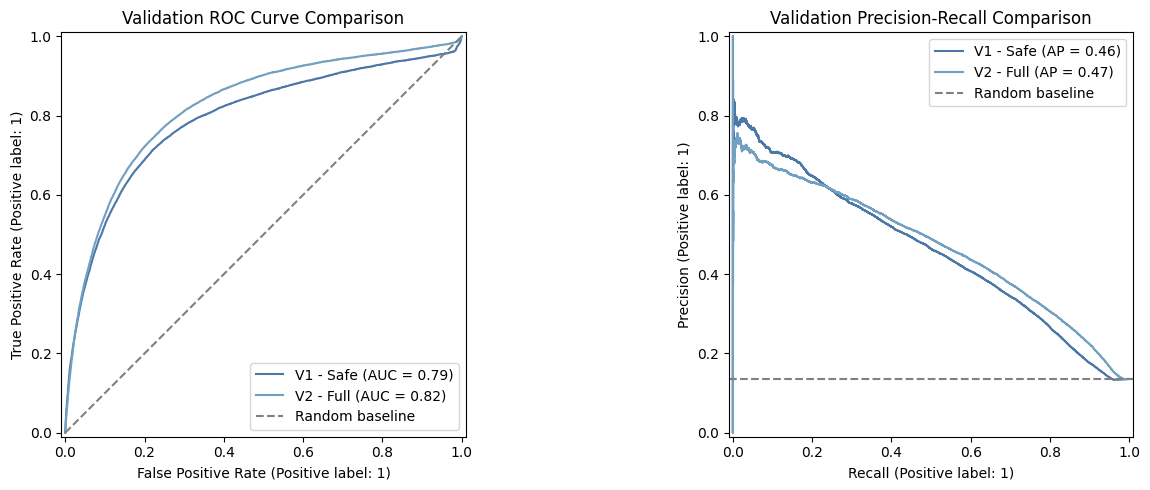

In [91]:
from sklearn.metrics import (
    RocCurveDisplay,
    PrecisionRecallDisplay
)

fig, axes = plt.subplots(
    1, 2,
    figsize=(14, 5)
)

for name, probabilities, color in [
    ("V1 - Safe", y_val_prob_safe, "#4C78A8"),
    ("V2 - Full", y_val_prob_full, "#72A0C1")
]:

    RocCurveDisplay.from_predictions(
        y_val,
        probabilities,
        name=name,
        color=color,
        ax=axes[0]
    )

    PrecisionRecallDisplay.from_predictions(
        y_val,
        probabilities,
        name=name,
        color=color,
        ax=axes[1]
    )

# Random classifier baseline
axes[0].plot(
    [0, 1],
    [0, 1],
    "--",
    color="grey",
    label="Random baseline"
)

axes[1].axhline(
    y_val.mean(),
    linestyle="--",
    color="grey",
    label="Random baseline"
)

axes[0].set_title("Validation ROC Curve Comparison")
axes[1].set_title("Validation Precision-Recall Comparison")

axes[0].legend()
axes[1].legend()

plt.tight_layout()
plt.show()

#### Curve Observations

- V2 has higher validation ROC-AUC (0.8238 versus 0.7924) and AP (0.4691 versus 0.4586).
- Both AP scores exceed the validation fraud prevalence of approximately 13.58%, indicating useful ranking ability relative to random ranking.
- A higher overall AUC or AP does not guarantee higher precision at every recall level or threshold. A comparison at a business-relevant operating point is still necessary.
- These ranking results do not resolve the uncertainty around Full-only customer snapshot features.

## 12. Potential Model Improvements

### 12.1 Decision Threshold Sensitivity Analysis

Both Logistic Regression versions demonstrated limited
recall at the default decision threshold of 0.5.

To investigate potential improvements, different
classification thresholds are evaluated using the
existing validation probabilities.

This analysis examines whether fraud detection coverage
can be increased while maintaining sufficiently high
precision and limiting unnecessary investigations.

No additional model is trained. The original model
configurations and logged experiment results remain
unchanged.

The results are exploratory and are not used to modify
the final test evaluation threshold.

In [92]:
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

threshold_results = []

thresholds = [
    0.05, 0.10, 0.15, 0.20, 0.25,
    0.30, 0.35, 0.40, 0.45, 0.50,
    0.55, 0.60, 0.65, 0.70
]

for version, probabilities in [
    ("V1 - Safe", y_val_prob_safe),
    ("V2 - Full", y_val_prob_full)
]:

    for threshold in thresholds:

        predictions = (
            probabilities >= threshold
        ).astype(int)

        tn_t, fp_t, fn_t, tp_t = confusion_matrix(
            y_val,
            predictions,
            labels=[0, 1]
        ).ravel()

        threshold_results.append({
            "Version": version,
            "Threshold": threshold,
            "Precision": precision_score(
                y_val, predictions, zero_division=0
            ),
            "Recall": recall_score(
                y_val, predictions, zero_division=0
            ),
            "F1-score": f1_score(
                y_val, predictions, zero_division=0
            ),
            "True Positives": tp_t,
            "False Positives": fp_t,
            "False Negatives": fn_t,
            "False Positive Rate": (
                fp_t / (fp_t + tn_t)
            ),
            "Flagged Orders": tp_t + fp_t
        })

threshold_df = pd.DataFrame(threshold_results)

display(threshold_df.round(4))

,Version,Threshold,Precision,Recall,F1-score,True Positives,False Positives,False Negatives,False Positive Rate,Flagged Orders
0,V1 - Safe,0.05,0.2022,0.8684,0.3281,16493,65063,2500,0.5382,81556
1,V1 - Safe,0.10,0.3146,0.7421,0.4419,14095,30709,4898,0.2540,44804
2,V1 - Safe,0.15,0.4105,0.5931,0.4852,11265,16180,7728,0.1339,27445
3,V1 - Safe,0.20,0.4859,0.4626,0.4740,8786,9295,10207,0.0769,18081
4,V1 - Safe,0.25,0.5447,0.3599,0.4335,6836,5713,12157,0.0473,12549
5,V1 - Safe,0.30,0.5968,0.2698,0.3716,5124,3462,13869,0.0286,8586
6,V1 - Safe,0.35,0.6485,0.1967,0.3019,3736,2025,15257,0.0168,5761
7,V1 - Safe,0.40,0.6977,0.1337,0.2244,2539,1100,16454,0.0091,3639
8,V1 - Safe,0.45,0.7209,0.0832,0.1492,1581,612,17412,0.0051,2193
9,V1 - Safe,0.50,0.7667,0.0531,0.0994,1009,307,17984,0.0025,1316


#### Threshold Results

Selected validation results are shown below. These are exploratory operating points, not additional trained model versions.

| Version | Threshold | Precision | Recall | False Positives | Flagged Orders |
|---|---:|---:|---:|---:|---:|
| Safe | 0.50 | 76.67% | 5.31% | 307 | 1,316 |
| Safe | 0.40 | 69.77% | 13.37% | 1,100 | 3,639 |
| Safe | 0.30 | 59.68% | 26.98% | 3,462 | 8,586 |
| Full | 0.50 | 64.53% | 16.53% | 1,726 | 4,866 |
| Full | 0.40 | 61.23% | 25.18% | 3,028 | 7,811 |

Reducing the Safe threshold from 0.50 to 0.40 increases detected fraud from 1,009 to 2,539 cases, while false positives increase from 307 to 1,100. Precision decreases by 6.90 percentage points. This illustrates a possible compromise, not an approved threshold.

### 12.2 Threshold Sensitivity Visualization

Plot precision, recall and F1-score against the candidate decision thresholds for each version. The dashed vertical line marks the original threshold of 0.5. This visualisation helps identify possible operating points without changing either trained model or its baseline configuration.

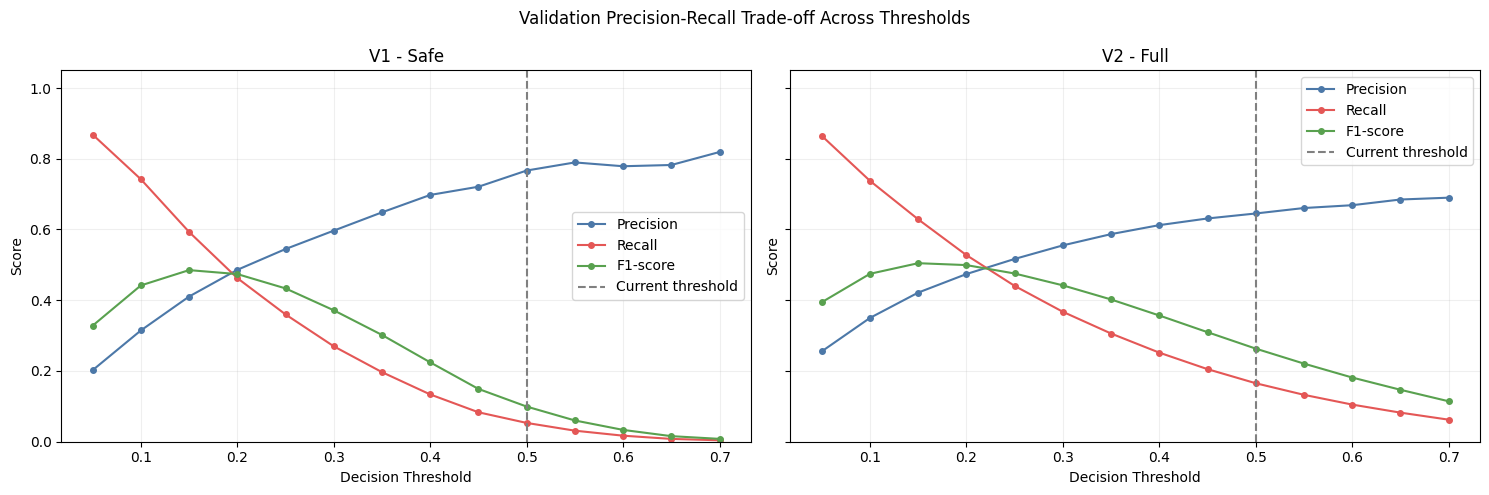

In [93]:
fig, axes = plt.subplots(
    1, 2,
    figsize=(15, 5),
    sharey=True
)

for ax, version in zip(
    axes,
    ["V1 - Safe", "V2 - Full"]
):

    subset = threshold_df[
        threshold_df["Version"] == version
    ]

    for metric, color in [
        ("Precision", "#4C78A8"),
        ("Recall", "#E45756"),
        ("F1-score", "#59A14F")
    ]:

        ax.plot(
            subset["Threshold"],
            subset[metric],
            marker="o",
            markersize=4,
            label=metric,
            color=color
        )

    ax.axvline(
        0.5,
        color="grey",
        linestyle="--",
        label="Current threshold"
    )

    ax.set_title(version)
    ax.set_xlabel("Decision Threshold")
    ax.set_ylabel("Score")
    ax.set_ylim(0, 1.05)

    ax.grid(alpha=0.2)
    ax.legend()

plt.suptitle(
    "Validation Precision-Recall Trade-off Across Thresholds"
)

plt.tight_layout()
plt.show()

#### Observations and Business Implications

- Lower thresholds increase recall and generally reduce precision, creating a larger investigation workload. Precision need not be strictly monotonic at every threshold.
- Among the evaluated thresholds, 0.15 gives the highest F1-score for both Safe (0.4852) and Full (0.5047). However, their precision values are only 41.05% and 42.16%, respectively; maximising F1 alone would not reflect the stakeholder's precision-first preference.
- A Safe threshold of 0.40 is worth investigating as a potential compromise, but recall remains limited. A threshold should ultimately be chosen using an agreed minimum recall, acceptable precision and investigation capacity on validation data only.
- The Product Owner has not specified numerical acceptance thresholds. No alternative operating point is therefore claimed to satisfy the business requirement, and the original threshold of 0.5 remains unchanged for the baseline experiments and planned final test evaluation.
- Full-only customer snapshot features remain unverified, regardless of threshold performance.

## 13. Model Interpretability

### 13.1 Logistic Regression Coefficient Analysis

Logistic Regression provides interpretable coefficients
that describe the relationship between prediction features
and the estimated log-odds of fraud.

Since StandardScaler is applied before model training,
the standardised coefficients are examined to compare
the relative influence of different predictors.

- Positive coefficients indicate an increase in predicted
  fraud log-odds when the feature increases, holding other
  features constant.
- Negative coefficients indicate a decrease in predicted
  fraud log-odds.
- Larger absolute coefficients indicate a stronger
  association within the fitted model.

Both model versions are examined to understand how the
additional customer snapshot features influence the
Full model's predictions.

Coefficient interpretation does not establish causation
and must account for correlations between predictors.

In [95]:
def extract_coefficients(model, feature_names):
    """Extract standardised Logistic Regression coefficients."""

    classifier = model.named_steps["classifier"]

    coefficients = classifier.coef_[0]

    assert len(coefficients) == len(feature_names)

    assert list(model.feature_names_in_) == list(feature_names)

    coefficient_df = pd.DataFrame({
        "Feature": list(feature_names),
        "Coefficient": coefficients
    })

    coefficient_df["Absolute Coefficient"] = (
        coefficient_df["Coefficient"].abs()
    )

    coefficient_df["Direction"] = np.where(
        coefficient_df["Coefficient"] > 0,
        "Positive",
        np.where(
            coefficient_df["Coefficient"] < 0,
            "Negative",
            "Neutral"
        )
    )

    return coefficient_df.sort_values(
        "Absolute Coefficient",
        ascending=False
    ).reset_index(drop=True)


# Extract coefficients from both trained pipelines
coef_safe = extract_coefficients(
    model_safe,
    X_train_safe.columns
)

coef_full = extract_coefficients(
    model_full,
    X_train_full.columns
)

print("V1 — Safe Dataset: Top 15 Coefficients")
display(coef_safe.head(15).round(4))

print("\nV2 — Full Dataset: Top 15 Coefficients")
display(coef_full.head(15).round(4))

V1 — Safe Dataset: Top 15 Coefficients


,Feature,Coefficient,Absolute Coefficient,Direction
0,country_code_PK,0.5457,0.5457,Positive
1,account_age_days,-0.4894,0.4894,Negative
2,country_code_MY,-0.4667,0.4667,Negative
3,country_code_BD,0.3638,0.3638,Positive
4,log_order_value,0.3207,0.3207,Positive
5,log_num_items_ordered,0.1612,0.1612,Positive
6,country_code_TH,-0.1451,0.1451,Negative
7,payment_method_credit_card,-0.0932,0.0932,Negative
8,country_code_PH,-0.0845,0.0845,Negative
9,payment_method_payment_on_delivery,0.0796,0.0796,Positive



V2 — Full Dataset: Top 15 Coefficients


,Feature,Coefficient,Absolute Coefficient,Direction
0,log_num_associated_customers,0.6983,0.6983,Positive
1,country_code_PK,0.5235,0.5235,Positive
2,country_code_MY,-0.4910,0.4910,Negative
3,log_order_value,0.4760,0.4760,Positive
4,log_total_payment_last_50days,-0.4055,0.4055,Negative
5,account_age_days,-0.3983,0.3983,Negative
6,country_code_BD,0.3289,0.3289,Positive
7,log_num_orders_last_50days,-0.2624,0.2624,Negative
8,log_num_cancelled_orders_last_50days,0.2544,0.2544,Positive
9,log_num_items_ordered,0.1804,0.1804,Positive


### Observations

**Version 1 — Safe Dataset**

- `country_code_PK` has the largest positive coefficient
  (0.5457), followed by `country_code_BD` (0.3638)
  and `log_order_value` (0.3207).
- `account_age_days` has the strongest negative
  coefficient (-0.4894), suggesting that older customer
  accounts are associated with lower predicted fraud risk.
- Higher order values and larger order quantities are
  positively associated with predicted fraud risk.

**Version 2 — Full Dataset**

- `log_num_associated_customers` has the largest
  absolute coefficient (0.6983).
- `log_total_payment_last_50days` has a relatively
  strong negative coefficient (-0.4055).
- Customer behavioural features provide additional
  predictive information beyond the order-level
  and account-age features.

These coefficients represent associations within the
fitted models rather than causal relationships.

### 13.2 Comparison of Influential Predictors

The 15 features with the largest absolute coefficients
are visualised for each model version.

A common horizontal axis is used to enable direct
comparison of coefficient magnitudes.

This analysis examines whether the additional customer
snapshot features appear among the Full model's most
influential predictors.

It also helps identify differences in how the two
models use shared features to estimate fraud risk.

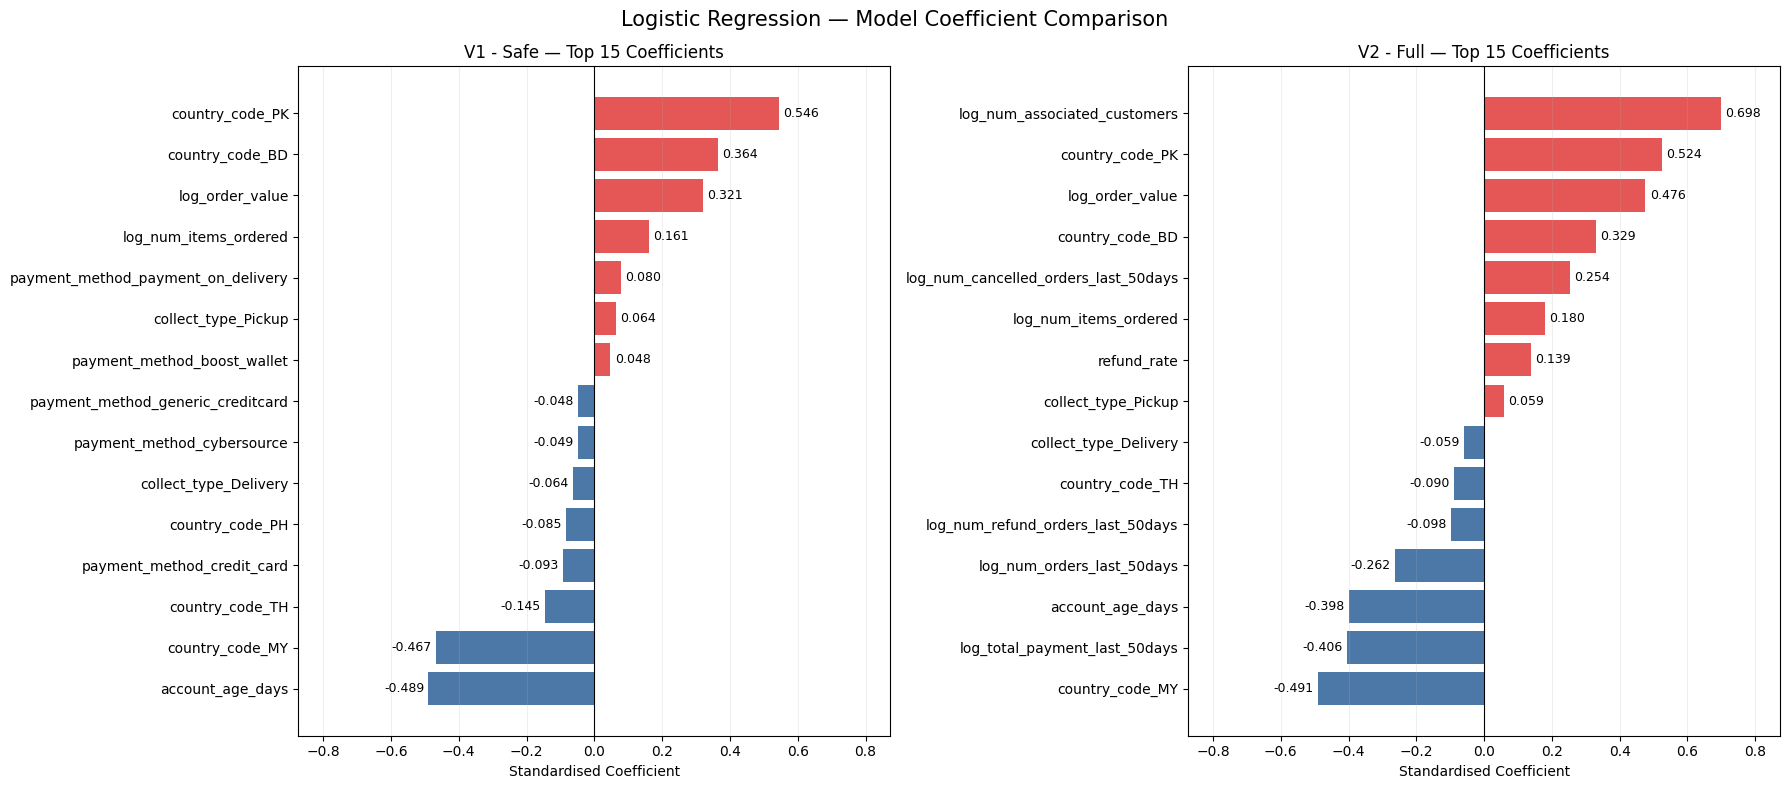

In [96]:
fig, axes = plt.subplots(
    1, 2,
    figsize=(18, 8),
    sharex=True
)

for ax, coef_df, version in [
    (axes[0], coef_safe, "V1 - Safe"),
    (axes[1], coef_full, "V2 - Full")
]:

    top_coef = (
        coef_df.head(15)
        .sort_values("Coefficient")
    )

    colors = [
        "#E45756" if value > 0 else "#4C78A8"
        for value in top_coef["Coefficient"]
    ]

    bars = ax.barh(
        top_coef["Feature"],
        top_coef["Coefficient"],
        color=colors
    )

    ax.bar_label(
        bars,
        fmt="%.3f",
        padding=3,
        fontsize=9
    )

    ax.axvline(
        0,
        color="black",
        linewidth=0.8
    )

    ax.set_title(f"{version} — Top 15 Coefficients")
    ax.set_xlabel("Standardised Coefficient")

    ax.grid(
        axis="x",
        alpha=0.2
    )

# Apply the same horizontal scale
max_coef = max(
    coef_safe["Absolute Coefficient"].max(),
    coef_full["Absolute Coefficient"].max()
)

for ax in axes:
    ax.set_xlim(
        -max_coef * 1.25,
        max_coef * 1.25
    )

plt.suptitle(
    "Logistic Regression — Model Coefficient Comparison",
    fontsize=15
)

plt.tight_layout()
plt.show()

### Observations

- The major shared predictors maintain consistent
  coefficient directions across both model versions.
- `log_order_value` increases from 0.3207 in the Safe
  model to 0.4760 in the Full model, indicating a stronger
  conditional association with predicted fraud risk.
- The absolute coefficient of `account_age_days`
  decreases from 0.4894 to 0.3983 after customer
  snapshot features are introduced.
- This suggests that some predictive information
  provided by account age may overlap with customer
  behavioural information.
- The Delivery and Pickup indicators have equal
  coefficients with opposite signs, consistent with
  their perfect negative correlation identified
  during EDA.
- Country-related coefficients reflect historical
  geographical patterns and should not be interpreted
  as evidence that geography causes fraud.

Overall, adding customer snapshot features changes
how the model distributes predictive information
across its features.

### 13.3 Influence of Customer Snapshot Features

The Full model contains 10 customer snapshot features
that are excluded from the Safe model.

Their standardised coefficients are examined to assess
their relative influence within the fitted model.

This analysis supports the investigation of potential
temporal data leakage and helps explain differences
between the two model versions.

A large coefficient does not prove data leakage.
Feature availability must be verified against the
actual time of fraud assessment.

In [97]:
from src.data_processing import SNAPSHOT_FEATURES

# Identify feature groups
coef_full["Feature Group"] = np.where(
    coef_full["Feature"].isin(SNAPSHOT_FEATURES),
    "Customer Snapshot",
    "Shared Feature"
)

snapshot_coef = coef_full[
    coef_full["Feature Group"] == "Customer Snapshot"
].copy()

print("Customer Snapshot Feature Coefficients")
display(snapshot_coef.round(4))

# Examine the top 15 predictors
top_15_full = coef_full.head(15)

snapshot_in_top_15 = (
    top_15_full["Feature Group"] == "Customer Snapshot"
).sum()

print(
    "Customer snapshot features among top 15:",
    snapshot_in_top_15
)

Customer Snapshot Feature Coefficients


,Feature,Coefficient,Absolute Coefficient,Direction,Feature Group
0,log_num_associated_customers,0.6983,0.6983,Positive,Customer Snapshot
4,log_total_payment_last_50days,-0.4055,0.4055,Negative,Customer Snapshot
7,log_num_orders_last_50days,-0.2624,0.2624,Negative,Customer Snapshot
8,log_num_cancelled_orders_last_50days,0.2544,0.2544,Positive,Customer Snapshot
10,refund_rate,0.1387,0.1387,Positive,Customer Snapshot
11,log_num_refund_orders_last_50days,-0.0975,0.0975,Negative,Customer Snapshot
16,cancel_rate,-0.0551,0.0551,Negative,Customer Snapshot
23,mobile_verified,0.0353,0.0353,Positive,Customer Snapshot
24,associated_capped,-0.0332,0.0332,Negative,Customer Snapshot
29,avg_payment_per_order,0.0214,0.0214,Positive,Customer Snapshot


Customer snapshot features among top 15: 6


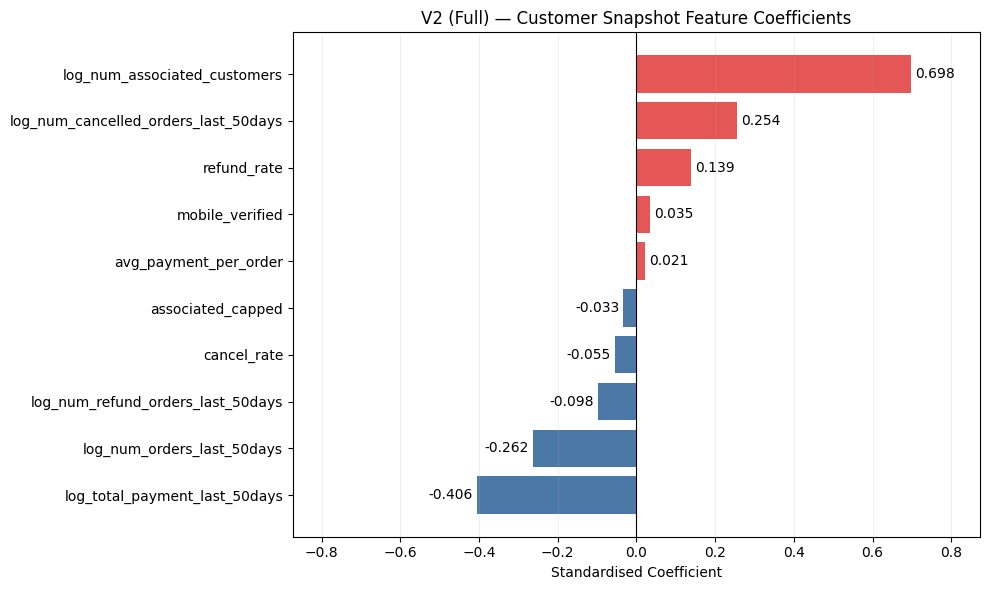

In [98]:
plot_df = snapshot_coef.sort_values("Coefficient")

fig, ax = plt.subplots(figsize=(10, 6))

colors = [
    "#E45756" if value > 0 else "#4C78A8"
    for value in plot_df["Coefficient"]
]

bars = ax.barh(
    plot_df["Feature"],
    plot_df["Coefficient"],
    color=colors
)

ax.bar_label(
    bars,
    fmt="%.3f",
    padding=3
)

ax.axvline(
    0,
    color="black",
    linewidth=0.8
)

ax.set_xlim(
    -max_coef * 1.25,
    max_coef * 1.25
)

ax.set_title(
    "V2 (Full) — Customer Snapshot Feature Coefficients"
)

ax.set_xlabel("Standardised Coefficient")

ax.grid(axis="x", alpha=0.2)

plt.tight_layout()
plt.show()

### Observations

- Six of the Full model's 15 largest absolute
  coefficients belong to customer snapshot features,
  representing 40% of the top-ranked predictors.
- `log_num_associated_customers` has the strongest
  positive coefficient (0.6983), suggesting that
  associated customer activity provides an important
  predictive signal within the fitted model.
- Historical payment amounts and order frequency
  have negative coefficients, while cancellation
  count and refund rate have positive coefficients.
- Interestingly, `refund_rate` has a positive
  coefficient (0.1387), whereas
  `log_num_refund_orders_last_50days` has a negative
  coefficient (-0.0975).
- These differing directions may reflect overlapping
  information and correlations between refund counts,
  refund ratios and order frequency.

**Business implications**

The coefficient results indicate that customer snapshot
features contribute to the Full model's predictions.

However, their point-in-time availability remains
unconfirmed. Their predictive value does not justify
using information that would be unavailable during
actual fraud assessment.

The Full model should therefore remain an exploratory
comparison rather than a deployment candidate until
feature availability is verified.

### 13.4 Interpretability Limitations

Several limitations must be considered when interpreting
Logistic Regression coefficients:

- Standardised coefficients represent changes in fraud
  log-odds per standard deviation rather than per
  original measurement unit.
- Correlated predictors may share predictive information,
  making individual coefficients difficult to interpret.
- L2 regularisation reduces coefficient instability
  but does not eliminate multicollinearity.
- Country and payment-related coefficients reflect
  patterns observed in the historical training data
  rather than causal relationships.
- Large coefficients for customer snapshot features
  do not establish that these features are available
  at the time of fraud assessment.

Therefore, coefficient analysis should be interpreted
alongside the validation results, business requirements
and feature availability constraints.

## 14. Final Test Evaluation

### 14.1 Test Predictions

After completing model development and validation
analysis, both Logistic Regression versions are evaluated
using the unseen chronological test dataset.

The original model configurations and decision threshold
of 0.5 are retained.

The test dataset is not used for hyperparameter tuning,
threshold selection or further model development.

This provides an independent assessment of model
performance on later orders.

In [99]:
# Generate test probabilities using the fitted models
y_test_prob_safe = model_safe.predict_proba(
    X_test_safe
)[:, 1]

y_test_prob_full = model_full.predict_proba(
    X_test_full
)[:, 1]

# Apply the original decision threshold
y_test_pred_safe = (
    y_test_prob_safe >= THRESHOLD
).astype(int)

y_test_pred_full = (
    y_test_prob_full >= THRESHOLD
).astype(int)

test_prediction_summary = pd.DataFrame({
    "Version": [
        "V1 - Safe",
        "V2 - Full"
    ],
    "Test Records": [
        len(y_test),
        len(y_test)
    ],
    "Actual Fraud Cases": [
        y_test.sum(),
        y_test.sum()
    ],
    "Predicted Fraud Cases": [
        y_test_pred_safe.sum(),
        y_test_pred_full.sum()
    ],
    "Decision Threshold": [
        THRESHOLD,
        THRESHOLD
    ]
})

display(test_prediction_summary)

,Version,Test Records,Actual Fraud Cases,Predicted Fraud Cases,Decision Threshold
0,V1 - Safe,144122,17835,2710,0.5
1,V2 - Full,144122,17835,7559,0.5


### 14.2 Test Evaluation and MLflow Logging

The final test metrics are calculated using the shared
classification evaluation utilities.

The results are recorded in the existing MLflow runs
for Version 1 and Version 2, ensuring that each run
contains its corresponding training, validation and
test results.

Test confusion matrices and precision-recall curves
are also stored as evaluation artifacts.

No additional model versions or experiment runs
are created.

In [100]:
# Confirm that logging targets the local training server
assert mlflow.get_tracking_uri() == (
    "http://127.0.0.1:5004"
)

assert mlflow.active_run() is None
assert THRESHOLD == 0.5

# Log V1 Safe test results to its existing run
with mlflow.start_run(run_id=run_id_safe):

    test_metrics_safe = log_classification_metrics(
        y_true=y_test,
        y_prob=y_test_prob_safe,
        threshold=THRESHOLD,
        split="test"
    )

    log_evaluation_artifacts(
        y_true=y_test,
        y_prob=y_test_prob_safe,
        feature_names=X_test_safe.columns,
        threshold=THRESHOLD,
        split="test"
    )

    mlflow.log_param(
        "test_records",
        len(y_test)
    )


# Log V2 Full test results to its existing run
with mlflow.start_run(run_id=run_id_full):

    test_metrics_full = log_classification_metrics(
        y_true=y_test,
        y_prob=y_test_prob_full,
        threshold=THRESHOLD,
        split="test"
    )

    log_evaluation_artifacts(
        y_true=y_test,
        y_prob=y_test_prob_full,
        feature_names=X_test_full.columns,
        threshold=THRESHOLD,
        split="test"
    )

    mlflow.log_param(
        "test_records",
        len(y_test)
    )

print("V1 Safe test results logged successfully.")
print("V2 Full test results logged successfully.")

🏃 View run abby_logistic_regression_safe_v1 at: http://127.0.0.1:5004/#/experiments/1/runs/53cba4b45adf40549f43e9d523ffc17e
🧪 View experiment at: http://127.0.0.1:5004/#/experiments/1
🏃 View run abby_logistic_regression_full_v2 at: http://127.0.0.1:5004/#/experiments/1/runs/86b4be614e394fa2ac73d90c6508dcb3
🧪 View experiment at: http://127.0.0.1:5004/#/experiments/1
V1 Safe test results logged successfully.
V2 Full test results logged successfully.


### 14.3 Final Test Performance Comparison

The final test performance of both Logistic Regression
versions is compared using six evaluation metrics.

Precision remains the primary business metric, while
recall is examined to determine whether the models
provide sufficient fraud detection coverage.

The results are also compared with validation performance
to assess generalisation across chronological periods.

In [101]:
test_comparison = pd.DataFrame({
    "Metric": metric_labels,
    "V1 - Safe": [
        test_metrics_safe[f"test_{m}"]
        for m in metric_names
    ],
    "V2 - Full": [
        test_metrics_full[f"test_{m}"]
        for m in metric_names
    ]
})

test_comparison["Difference (Full - Safe)"] = (
    test_comparison["V2 - Full"] -
    test_comparison["V1 - Safe"]
)

display(test_comparison.round(4))

,Metric,V1 - Safe,V2 - Full,Difference (Full - Safe)
0,Accuracy,0.8816,0.8863,0.0047
1,Precision,0.6424,0.5961,-0.0463
2,Recall,0.0976,0.2526,0.1550
3,F1-score,0.1695,0.3549,0.1854
4,PR-AUC (Average Precision),0.3981,0.4501,0.0520
5,ROC-AUC,0.7711,0.8215,0.0504


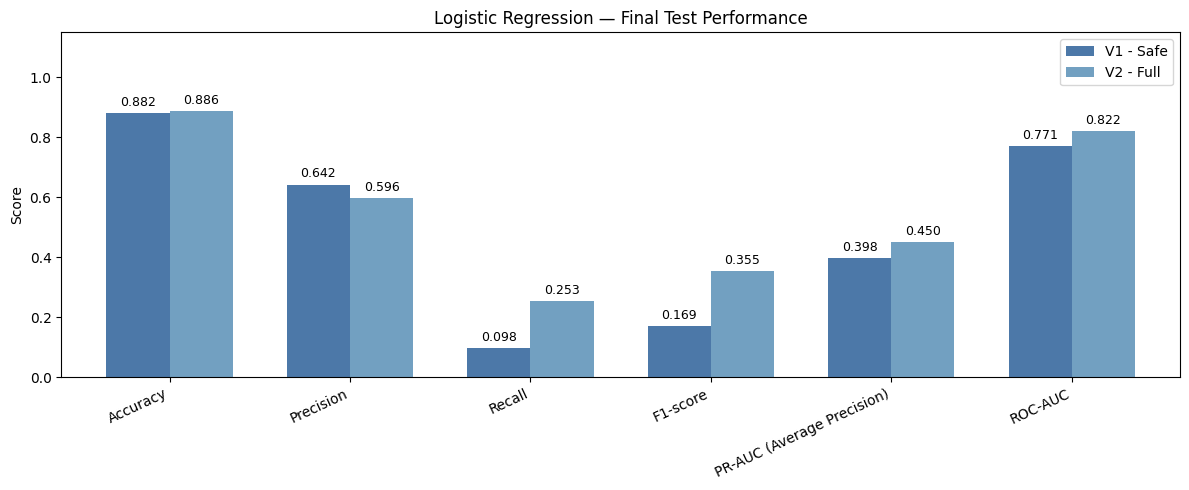

In [102]:
ax = test_comparison.plot(
    x="Metric",
    y=["V1 - Safe", "V2 - Full"],
    kind="bar",
    figsize=(12, 5),
    color=["#4C78A8", "#72A0C1"],
    width=0.7
)

for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.3f",
        padding=3,
        fontsize=9
    )

ax.set_title(
    "Logistic Regression — Final Test Performance"
)

ax.set_ylabel("Score")
ax.set_xlabel("")
ax.set_ylim(0, 1.15)

plt.xticks(rotation=25, ha="right")
plt.legend()
plt.tight_layout()
plt.show()

### Observations

- The Safe model achieved higher test precision (64.24%)
  than the Full model (59.61%), a difference of 4.63
  percentage points.

- The Full model achieved substantially higher recall
  (25.26%) than the Safe model (9.76%), detecting a
  greater proportion of fraudulent orders.

- The Full model also achieved a higher F1-score
  (0.3549), Average Precision (0.4501) and ROC-AUC
  (0.8215), indicating better overall discrimination
  between fraudulent and legitimate orders.

- However, the Safe and Full models missed approximately
  90.24% and 74.74% of fraudulent orders, respectively.

- Although both models achieved accuracy above 88%,
  their relatively low recall demonstrates why accuracy
  alone is insufficient for fraud detection evaluation.

**Business implications**

The Safe model better aligns with the stakeholder's
precision priority and has lower potential temporal
leakage risk. However, its limited recall prevents it
from fully satisfying the business objective.

The Full model provides greater fraud detection coverage
but produces a lower proportion of correct fraud alerts.

Furthermore, the availability of customer snapshot
features at the time of fraud assessment remains
unconfirmed, limiting its suitability for deployment.

### 14.4 Generalisation Across Data Splits

Training, validation and test performance are compared
to assess model stability across different chronological
periods.

This comparison helps identify potential overfitting,
performance deterioration and changes in predictive
effectiveness on unseen data.

Differences in fraud prevalence across the three splits
are considered when interpreting the results.

In [103]:
all_split_results = []

for version, metrics_by_split in [
    (
        "V1 - Safe",
        [
            train_metrics_safe,
            val_metrics_safe,
            test_metrics_safe
        ]
    ),
    (
        "V2 - Full",
        [
            train_metrics_full,
            val_metrics_full,
            test_metrics_full
        ]
    )
]:

    for split, metrics in zip(
        ["train", "val", "test"],
        metrics_by_split
    ):

        all_split_results.append({
            "Version": version,
            "Split": split,
            **{
                label: metrics[f"{split}_{metric}"]
                for metric, label in zip(
                    metric_names,
                    metric_labels
                )
            }
        })

all_split_comparison = pd.DataFrame(
    all_split_results
)

display(all_split_comparison.round(4))

,Version,Split,Accuracy,Precision,Recall,F1-score,PR-AUC (Average Precision),ROC-AUC
0,V1 - Safe,train,0.9005,0.6018,0.0589,0.1073,0.3165,0.7741
1,V1 - Safe,val,0.8692,0.7667,0.0531,0.0994,0.4586,0.7924
2,V1 - Safe,test,0.8816,0.6424,0.0976,0.1695,0.3981,0.7711
3,V2 - Full,train,0.9039,0.5806,0.1925,0.2891,0.4309,0.8600
4,V2 - Full,val,0.8743,0.6453,0.1653,0.2632,0.4691,0.8238
5,V2 - Full,test,0.8863,0.5961,0.2526,0.3549,0.4501,0.8215


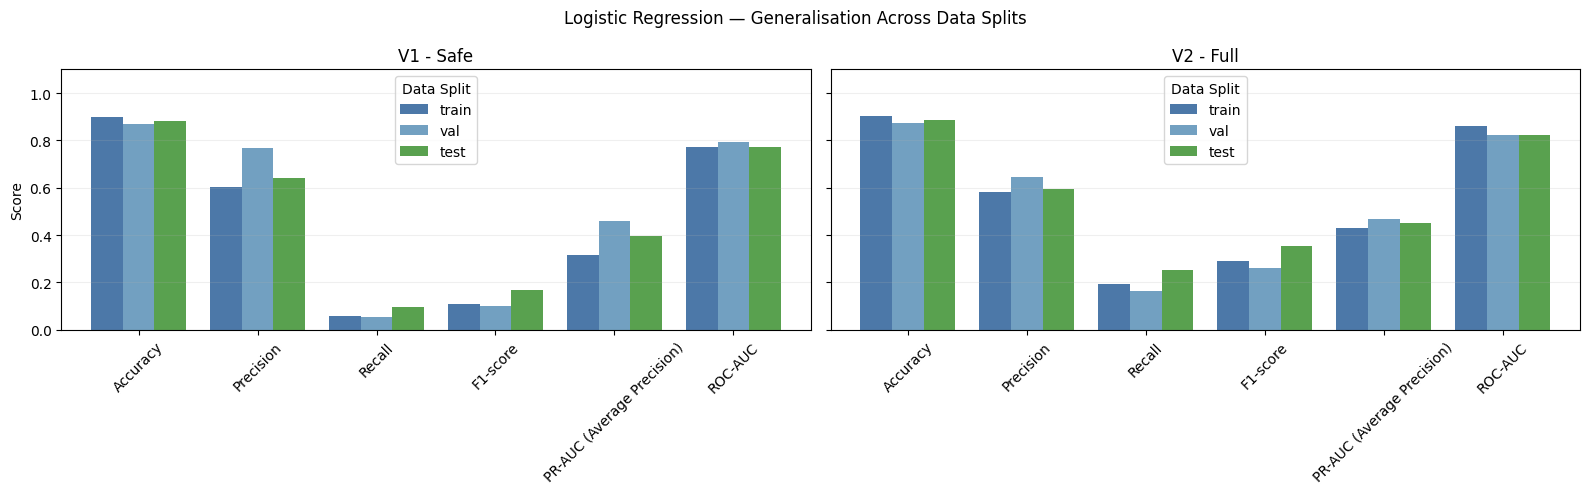

In [104]:
fig, axes = plt.subplots(
    1, 2,
    figsize=(16, 5),
    sharey=True
)

for ax, version in zip(
    axes,
    ["V1 - Safe", "V2 - Full"]
):

    subset = all_split_comparison[
        all_split_comparison["Version"] == version
    ]

    subset.set_index("Split")[
        metric_labels
    ].T.plot(
        kind="bar",
        ax=ax,
        color=[
            "#4C78A8",
            "#72A0C1",
            "#59A14F"
        ],
        width=0.8
    )

    ax.set_title(version)
    ax.set_ylabel("Score")
    ax.set_xlabel("")
    ax.set_ylim(0, 1.1)
    ax.tick_params(axis="x", rotation=45)
    ax.legend(title="Data Split")
    ax.grid(axis="y", alpha=0.2)

plt.suptitle(
    "Logistic Regression — Generalisation Across Data Splits"
)

plt.tight_layout()
plt.show()

### Observations

**Version 1 — Safe Dataset**

- ROC-AUC remains relatively consistent across training
  (0.7741), validation (0.7924) and testing (0.7711).

- Precision decreases from 76.67% on the validation
  set to 64.24% on the test set, while recall increases
  from 5.31% to 9.76%.

- Average Precision decreases from 0.4586 to 0.3981
  between validation and testing, suggesting that fraud
  ranking performance varies across chronological periods.

- The consistently low recall indicates that the default
  classification threshold remains a major limitation.

**Version 2 — Full Dataset**

- ROC-AUC decreases from 0.8600 during training to
  0.8238 during validation and 0.8215 during testing.

- Validation and test ROC-AUC values are relatively
  stable, although the training-to-test performance
  gap indicates some deterioration on unseen data.

- Recall increases from 16.53% during validation to
  25.26% during testing, while precision decreases
  from 64.53% to 59.61%.

- Average Precision remains relatively consistent
  across the three chronological splits.

**Overall generalisation**

Neither model demonstrates clear evidence of severe
overfitting based on the observed evaluation metrics.

However, differences in fraud prevalence and potential
changes in customer behaviour across chronological
periods may influence model performance.

The results reinforce the importance of chronological
evaluation and continuous model performance monitoring
when new data becomes available.

## 15. Further Potential Improvements

Although both Logistic Regression versions were
successfully trained and evaluated, several improvements
could be considered in future iterations.

### 15.1 Decision Threshold Optimisation

The validation threshold sensitivity analysis demonstrates
that reducing the classification threshold can improve
recall without retraining the model.

A suitable operating threshold could be selected by
maximising recall while maintaining a stakeholder-approved
minimum precision level.

The investigation workload and number of false positives
should also be considered.

### 15.2 Class Weighting

The training dataset contains approximately 10.15%
fraudulent orders.

Class weighting could increase the importance of
fraudulent observations during model training and
potentially improve minority-class detection.

However, this may increase false positives and reduce
precision. Its effectiveness should therefore be evaluated
using the validation dataset.

### 15.3 Hyperparameter Tuning

The regularisation parameter C could be tuned to
investigate whether different regularisation strengths
improve model performance and generalisation.

Chronological validation should be retained during
hyperparameter selection to prevent future information
from influencing model development.

### 15.4 Feature Interactions

Logistic Regression uses a linear relationship between
the input features and predicted fraud log-odds.

Interaction features could help capture more complex
fraud patterns, such as relationships between account
age, order value and payment method.

All additional features must satisfy the stakeholder's
point-in-time availability requirements.

### 15.5 Point-in-Time Customer Features

The Full model demonstrates the potential predictive
value of customer behavioural information.

Future improvements could reconstruct historical
customer statistics using only information available
before each order assessment.

This would allow useful behavioural features to be
incorporated while reducing temporal leakage risk.

### 15.6 Model Monitoring and Retraining

Precision, recall, Average Precision and fraud prevalence
should be monitored as new data becomes available.

Automated retraining could help maintain model
effectiveness when customer behaviour or fraud patterns
change.

These improvements are proposed for future development.
The original two model versions remain unchanged to
preserve a controlled and reproducible comparison.

## 16. Model Reproducibility and Verification

### 16.1 Model Reload and Prediction Verification

Both trained Logistic Regression pipelines are reloaded
from the MLflow tracking server using their logged model
URIs.

The reloaded models are used to generate fraud
probabilities and binary predictions on the test dataset.

These predictions are compared with the original model
outputs to verify that model serialisation and retrieval
preserve predictive behaviour.

This verification supports reliable model management,
reproducibility and future automated retraining.

In [105]:
import mlflow.sklearn

# Reload both models from MLflow
loaded_model_safe = mlflow.sklearn.load_model(
    model_info_safe.model_uri
)

loaded_model_full = mlflow.sklearn.load_model(
    model_info_full.model_uri
)

verification_results = []

for version, loaded_model, X_test, original_prob in [
    (
        "V1 - Safe",
        loaded_model_safe,
        X_test_safe,
        y_test_prob_safe
    ),
    (
        "V2 - Full",
        loaded_model_full,
        X_test_full,
        y_test_prob_full
    )
]:

    # Generate probabilities using the reloaded model
    loaded_prob = loaded_model.predict_proba(
        X_test
    )[:, 1]

    loaded_pred = (
        loaded_prob >= THRESHOLD
    ).astype(int)

    original_pred = (
        original_prob >= THRESHOLD
    ).astype(int)

    # Verify prediction consistency
    np.testing.assert_allclose(
        loaded_prob,
        original_prob,
        rtol=1e-10,
        atol=1e-12
    )

    np.testing.assert_array_equal(
        loaded_pred,
        original_pred
    )

    max_difference = np.max(
        np.abs(loaded_prob - original_prob)
    )

    verification_results.append({
        "Version": version,
        "Test Records": len(X_test),
        "Model Reloaded": "Passed",
        "Probability Consistency": "Passed",
        "Prediction Consistency": "Passed",
        "Maximum Probability Difference": max_difference
    })

verification_df = pd.DataFrame(
    verification_results
)

display(verification_df)

print("Both models passed reload verification.")

,Version,Test Records,Model Reloaded,Probability Consistency,Prediction Consistency,Maximum Probability Difference
0,V1 - Safe,144122,Passed,Passed,Passed,0.0
1,V2 - Full,144122,Passed,Passed,Passed,0.0


Both models passed reload verification.


### Observations

- Both Logistic Regression pipelines were successfully
  reloaded from the MLflow tracking server.
- All 144,122 test records were used to verify prediction
  consistency for each model version.
- The maximum probability difference was 0.0 for both
  models, demonstrating identical probability outputs.
- Binary predictions were also identical before and
  after model reloading.
- The fitted StandardScaler and Logistic Regression
  classifier were successfully preserved within each
  logged pipeline.

These results demonstrate that model serialisation and
retrieval preserve the original predictive behaviour,
supporting reliable model reuse and deployment.

### 16.2 MLflow Run Completeness Verification

The MLflow tracking records are inspected to verify
that both model versions contain their required
evaluation metrics, model identifiers and artifacts.

This ensures that the experiments are sufficiently
documented for subsequent model comparison and
model registry operations.

In [106]:
client = mlflow.MlflowClient()

required_metrics = {
    f"{split}_{metric}"
    for split in ["train", "val", "test"]
    for metric in metric_names
}

required_artifacts = {
    "evaluation/val_confusion_matrix.png",
    "evaluation/val_pr_curve.png",
    "evaluation/test_confusion_matrix.png",
    "evaluation/test_pr_curve.png",
    "metadata/features.json"
}

def collect_artifact_paths(run_id, path=None):

    paths = set()

    for artifact in client.list_artifacts(
        run_id, path
    ):
        if artifact.is_dir:
            paths.update(
                collect_artifact_paths(
                    run_id, artifact.path
                )
            )
        else:
            paths.add(artifact.path)

    return paths


run_verification = []

for version, run_id in [
    ("V1 - Safe", run_id_safe),
    ("V2 - Full", run_id_full)
]:

    stored_run = client.get_run(run_id)

    logged_metrics = set(
        stored_run.data.metrics.keys()
    )

    artifact_paths = collect_artifact_paths(
        run_id
    )

    missing_metrics = (
        required_metrics - logged_metrics
    )

    missing_artifacts = (
        required_artifacts - artifact_paths
    )

    assert stored_run.info.status == "FINISHED"
    assert not missing_metrics, missing_metrics
    assert not missing_artifacts, missing_artifacts

    run_verification.append({
        "Version": version,
        "Run ID": run_id,
        "Run Status": stored_run.info.status,
        "Evaluation Metrics": (
            f"{len(required_metrics & logged_metrics)}"
            f"/{len(required_metrics)}"
        ),
        "Required Artifacts": (
            f"{len(required_artifacts & artifact_paths)}"
            f"/{len(required_artifacts)}"
        )
    })

display(pd.DataFrame(run_verification))

print("Both MLflow runs passed completeness verification.")

,Version,Run ID,Run Status,Evaluation Metrics,Required Artifacts
0,V1 - Safe,53cba4b45adf40549f43e9d523ffc17e,FINISHED,18/18,5/5
1,V2 - Full,86b4be614e394fa2ac73d90c6508dcb3,FINISHED,18/18,5/5


Both MLflow runs passed completeness verification.


### Observations

- Both MLflow runs have a FINISHED status.
- All 18 required evaluation metrics were successfully
  recorded for each model version, covering training,
  validation and testing.
- All five required evaluation and feature metadata
  artifacts were successfully verified to be present.
- The original experiment runs were reused when logging
  final test results, avoiding unnecessary duplicate runs.

The results demonstrate consistent experiment tracking
and provide the necessary evaluation records for
subsequent model comparison and registry operations.

This verification was conducted on the persistent local
MLflow server. Shared AWS tracking verification remains
a subsequent integration task.

## 17. Conclusion

This notebook successfully developed and evaluated
two Logistic Regression versions for SP-buy fraud
detection using the team's shared feature datasets
and chronological data split.

### 17.1 Model Performance Summary

| Metric | V1 - Safe | V2 - Full |
|---|---:|---:|
| Number of features | 31 | 41 |
| Training time (s) | 1.9473 | 3.5282 |
| Validation precision | 0.7667 | 0.6453 |
| Validation recall | 0.0531 | 0.1653 |
| Validation F1-score | 0.0994 | 0.2632 |
| Validation Average Precision | 0.4586 | 0.4691 |
| Validation ROC-AUC | 0.7924 | 0.8238 |
| Test precision | 0.6424 | 0.5961 |
| Test recall | 0.0976 | 0.2526 |
| Test F1-score | 0.1695 | 0.3549 |
| Test Average Precision | 0.3981 | 0.4501 |
| Test ROC-AUC | 0.7711 | 0.8215 |

### 17.2 Business Assessment

The Safe model achieved higher precision on both
the validation and test datasets, aligning more
closely with the stakeholder's priority of minimising
unnecessary investigations of legitimate customers.

However, its low recall limits its effectiveness
in detecting fraudulent orders.

The Full model achieved better recall, F1-score,
Average Precision and ROC-AUC, demonstrating stronger
overall predictive performance.

Nevertheless, the availability of its additional
customer snapshot features at the time of fraud
assessment remains unconfirmed. Consequently, it
should not be selected for deployment until its
feature availability has been verified.

Neither version fully demonstrates the desired
balance of high precision and reasonable recall
at the default decision threshold of 0.5.

### 17.3 Recommended Model

Among the two Logistic Regression versions, the Safe
model is recommended as the more appropriate candidate
for further development because of its higher precision
and lower potential temporal leakage risk.

This recommendation is based on the validation results
and business constraints, with the test results providing
an independent assessment.

However, the Safe model is not recommended for immediate
deployment due to its insufficient fraud detection coverage.

The final Champion Model should be selected after
comparing all eligible team models against the
stakeholder's business requirements.

### 17.4 Future Improvements

Validation-based decision threshold optimisation
is recommended as a priority for future development.

Additional improvements include class weighting,
regularisation tuning, feature interactions and the
development of point-in-time customer behavioural
features.

These improvements should be evaluated without using
the final test dataset for model selection.

### 17.5 MLOps Readiness

Both Logistic Regression versions were successfully trained and recorded in MLflow with their parameters, evaluation metrics, trained pipelines and artifacts.

Model reload verification demonstrated identical probability outputs and binary predictions for all 144,122 test records.

Both experiment runs passed completeness verification, providing consistent records for subsequent team-level model comparison.

The existing model training logic can be standardised into reusable Python functions during PBI 5 to support future automated retraining and ETL integration.

Overall, Logistic Regression provides an interpretable and computationally efficient benchmark for the SP-buy fraud detection project.

All experiment logging and model reload verification were conducted on the persistent local MLflow server. Shared AWS MLflow integration remains a subsequent task under PBI 3.